<div style="width: 100%; clear: both;">
<div style="float: left; width: 50%;">
<img src="http://www.uoc.edu/portal/_resources/common/imatges/marca_UOC/UOC_Masterbrand.jpg" align="left">
</div>
<div style="float: right; width: 50%;">
<p style="margin: 0; padding-top: 22px; text-align:right;">M2.891 · Aprendizaje automático · PEC2</p>
<p style="margin: 0; text-align:right;">2026-1 · Máster universitario en Ciencia de datos (Data science)</p>
<p style="margin: 0; text-align:right; padding-button: 100px;">Estudios de Informática, Multimedia y Telecomunicación</p>
</div>
</div>
<div style="width:100%;">&nbsp;</div>
<br>

**Importante:** cada uno de los ejercicios puede suponer varios minutos de ejecución, por lo que la entrega debe hacerse en formato notebook y en formato html, donde se vea el código, los resultados y comentarios de cada ejercicio. Se puede exportar el notebook a html desde el menú File $\to$ Download as $\to$ HTML.

**Importante:** existe un tipo de celda especial para albergar texto. Este tipo de celda os será muy útil para responder a las diferentes preguntas teóricas planteadas a lo largo de cada PEC. Para cambiar el tipo de celda a este tipo, elegid en el menú: Cell $\to$ Cell Type $\to$ Markdown.

**Importante:** la solución planteada no debe utilizar métodos, funciones o parámetros declarados "deprecated" en futuras versiones.

**Importante:** es conveniente que utilicéis una semilla con un valor fijo (en este Notebook se os propone la variable _seed_ inicializada a 100) en todos aquellos métodos o funciones que contengan alguna componente aleatoria para aseguraros de que obtendréis siempre el mismo resultado en las distintas ejecuciones de vuestro código.

**Importante:** no olvidéis poner vuestro nombre y apellidos en la siguiente celda.

<div style="background-color: #ff9999; border-color: #dfb5b4; border-left: 5px solid #dfb5b4; padding: 0.5em;">
<strong>AVISO:</strong> tened cuidado, más podría ser menos. Si os excedéis en las respuestas, podríais tener penalización en la nota. Sed concisos, sintetizad lo que queréis remarcar e id al grano por favor.
</div>

<div class="alert alert-block alert-info">
<strong>Nombre y apellidos:</strong>
</div>

Adrián Moreno Garcia


# PEC 2 De la geometría a las decisiones
## Descubrir grupos que permiten tomar decisiones

En esta práctica estudiarás cómo cambian los grupos cuando cambia el algoritmo (1) **y cuando cambia la representación** (2).

1. Laboratorio de clustering.
2. ¿Qué arreglamos en la próxima release? Análisis de comentarios de videojuegos.

Todas las figuras deben elaborarse con **Matplotlib**. Usa títulos, ejes y leyendas legibles. Representa el ruido en gris.

**En el segundo ejercicio**:
 - El uso de MiniLM y Laya es para producir features, no es necesario entrenar ni ajustar sus pesos.
 - Se adjunta un CSV que contiene 2000 comentarios reales.
 - La inferencia en CPU puede tardar bastantes minutos, mide primero el piloto de veinte textos y planifica la ejecución (puedes reducir el número de muestras a 1000 si es excesivo en tu máquina).
 - La variable `N_REVIEWS` permite seleccionar un número de muestras para usar en el ejercicio, no la reduzcas a mitad del experimento.

In [97]:
from pathlib import Path
import gc
import json
import time
import truststore
truststore.inject_into_ssl()
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from threadpoolctl import threadpool_limits
from IPython.display import display
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.datasets import make_blobs, make_moons, make_circles
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from umap import UMAP
from sklearn.metrics import adjusted_rand_score, silhouette_score, normalized_mutual_info_score
from sklearn.preprocessing import normalize
from sklearn.neighbors import NearestNeighbors

seed = 100
rng = np.random.default_rng(seed)
threadpool_limits(limits=4)
DATA = Path('.')
CACHE = Path('_pec2_cache')
CACHE.mkdir(exist_ok=True)
pd.set_option('display.max_colwidth',None)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.titlesize': 12,
                     'axes.labelsize': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.facecolor': 'white'})

Funciones auxiliares para la PEC en las que te puedes apoyar (no es obligatorio usarlas). Las funciones están muy documentadas para facilitar su uso, no estamos esperando que documentes el código de la misma manera.

In [2]:
from pathlib import Path
import hashlib
import json
import textwrap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm


COLORS = ['#2563eb', '#f59e0b', '#059669', '#db2777', '#7c3aed', '#0891b2',
          '#ea580c', '#65a30d', '#475569', '#c026d3', '#0d9488', '#9333ea']


def complaint_question(aspect, complaint_examples):
    """Construye una pregunta binaria sobre una queja para Laya.

    Parámetros
    ----------
    aspect : str
        Aspecto en inglés que se quiere detectar (por ejemplo, "performance").
    complaint_examples : str
        Descripción en inglés de la queja.

    Return
    ------
    dict
        Esquema de respuesta binaria de Laya, con alternativas explícitas de queja y ausencia de queja.

    Ejemplo
    -------
    >>> questions = {"performance": complaint_question(
    ...     "performance", "Low FPS, stuttering or excessive lag.")}
    >>> features = laya_features(agent, df["text"], questions)
    """
    return {
        'type': 'noul',
        'instructions': f'Does this game review complain about {aspect}?',
        'labels': {'false': f'No {aspect} complaint', 'true': f'{aspect} complaint'},
        'criteria': {'false': f'{aspect} is praised or unmentioned; no complaint.',
                     'true': complaint_examples},
    }


def plot_groups(ax, xy, labels, title, size=16):
    """Scatter plot bidimensional con los puntos coloreados por grupo.

    Parámetros
    ----------
    ax : matplotlib.axes.Axes
        Eje en el que se dibuja.
    xy : numpy.ndarray con shape (n_muestras, 2)
        Coordenadas originales o proyección UMAP.
    labels : array de enteros de longitud n_muestras
        Grupo de cada punto, en el mismo orden que xy. El valor -1 representa ruido y se dibuja en gris. Los demás grupos usan la paleta COLORS.
    title : str
        Título de la figura.
    size : float, opcional
        Área de los marcadores en puntos cuadrados.

    Return
    ------
    None
        Modifica ax.

    Ejemplo
    -------
    >>> fig, ax = plt.subplots()
    >>> plot_groups(ax, xy, labels, "Grupos en UMAP")
    >>> ax.legend()
    >>> plt.show()
    """
    labels = np.asarray(labels)
    for label in sorted(np.unique(labels)):
        mask = labels == label
        color = '#a1a1aa' if label == -1 else COLORS[int(label) % len(COLORS)]
        ax.scatter(xy[mask, 0], xy[mask, 1], s=size, color=color, alpha=.75,
                   edgecolors='none', label='Ruido' if label == -1 else f'Grupo {label}')
    ax.set_title(title, fontweight='bold', pad=10)
    ax.set_xlabel('Coordenada 1')
    ax.set_ylabel('Coordenada 2')
    ax.spines[['top', 'right']].set_visible(False)


def heatmap(ax, matrix, rows, columns, title, cmap='Blues', vmin=0, vmax=1, annotate=True):
    """Mapa de calor con etiquetas y valores.

    Parámetros
    ----------
    ax : matplotlib.axes.Axes
        Eje en el que se dibuja.
    matrix : array de forma (n_filas, n_columnas)
        Valores.
    rows, columns : secuencias de str
        Etiquetas de filas y columnas (su longitud debe coincidir con la matrix).
    title : str
        Título del mapa de calor.
    cmap : str, opcional
        Paleta de Matplotlib.
    vmin, vmax : float, opcional
        Límites de la escala de color (por defecto, 0 y 1).
    annotate : bool, opcional
        Si es True, escribe cada valor con dos decimales.

    Return
    ------
    matplotlib.image.AxesImage
        Imagen que permite añadir una barra de color con fig.colorbar().

    Ejemplo
    -------
    >>> fig, ax = plt.subplots()
    >>> im = heatmap(ax, [[0.2, 0.8]], ["Grupo 0"],
    ...              ["Bugs", "Rendimiento"], "Perfil del grupo")
    >>> fig.colorbar(im, ax=ax)
    >>> plt.show()
    """
    matrix = np.asarray(matrix)
    im = ax.imshow(matrix, aspect='auto', cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_xticks(range(len(columns)), columns, rotation=35, ha='right')
    ax.set_yticks(range(len(rows)), rows)
    ax.set_title(title, fontweight='bold', pad=12)
    if annotate:
        for i in range(len(rows)):
            for j in range(len(columns)):
                ax.text(j, i, f'{matrix[i, j]:.2f}', ha='center', va='center',
                        color='white' if matrix[i, j] > (vmin + vmax) / 2 else '#18181b', fontsize=9)
    return im


def show_representatives(df, vectors, labels, max_groups=4, n=3):
    """Muestra comentarios cercanos al centro de los grupos más numerosos.

    Parámetros
    ----------
    df : pandas.DataFrame
        Comentarios con columnas review_id, game y text.
    vectors : array con shape (n_comentarios, n_variables)
        Representación usada para calcular la media de cada grupo y la distancia euclídea a ella.
    labels : array de longitud n_comentarios
        Etiquetas del clustering.
    max_groups : int, opcional
        Número máximo de grupos que se muestran.
    n : int, opcional
        Número máximo de comentarios que se imprimen por grupo.

    Return
    ------
    None
        
    Ejemplo
    -------
    >>> show_representatives(df, embeddings, labels, max_groups=4, n=3)
    """
    vectors, labels = np.asarray(vectors), np.asarray(labels)
    counts = pd.Series(labels[labels >= 0]).value_counts()
    for label in counts.head(max_groups).index:
        positions = np.flatnonzero(labels == label)
        mean = vectors[positions].mean(axis=0)
        order = positions[np.argsort(np.linalg.norm(vectors[positions] - mean, axis=1))[:n]]
        print(f'\nCLUSTER {label} | {len(positions)} comentarios')
        for position in order:
            row = df.iloc[position]
            print(f"  {row.review_id} · {row.game}\n  {textwrap.fill(row.text, width=100)}\n")


def laya_features(agent, texts, questions, cache_dir=Path('_pec2_cache/laya')):
    """Extrae features numéricas con Laya y guarda resultados.

    Parámetros
    ----------
    agent : agente Laya
        Modelo cargado con load_laya().
    texts : iterable de str
        Textos que se procesan en el orden recibido.
    questions : dict
        Nombres de preguntas y sus esquemas Laya. Admite "noul", "score" y "choice".
        Los nombres de las columnas resultantes deben ser únicos.
    cache_dir : str o pathlib.Path, opcional
        Carpeta de caché que se crea si no existe (como tarda bastante evita recálculos).

    Return
    ------
    pandas.DataFrame
        Una fila por texto, en el orden de entrada, con índice nuevo desde cero.
        
    Ejemplo
    -------
    >>> questions = {"performance": complaint_question(
    ...     "performance", "Low FPS, stuttering or excessive lag.")}
    >>> features = laya_features(agent, df["text"], questions)
    >>> features.head()
    """
    from importlib.metadata import version
    import time
    started = time.perf_counter()
    texts = list(texts)
    cache_dir = Path(cache_dir)
    cache_dir.mkdir(parents=True, exist_ok=True)
    identity = {'questions': questions, 'laya_version': version('laya'),
                'checkpoint': getattr(agent, '_pec2_revision', 'unspecified')}
    schema_hash = hashlib.sha256(json.dumps(identity, sort_keys=True).encode()).hexdigest()[:20]
    path = cache_dir / f'laya_{schema_hash}.json'
    cache = json.loads(path.read_text(encoding='utf-8')) if path.exists() else {'identity': identity, 'rows': {}}
    hits = sum(hashlib.sha256(text.encode('utf-8')).hexdigest() in cache['rows'] for text in texts)
    records = []
    keys = [column for key,q in questions.items()
            for column in (list(q['criteria']) if q['type']=='choice' else [key])]
    if len(keys)!=len(set(keys)):
        raise ValueError('Usa nombres de opciones únicos entre preguntas choice.')
    for text in tqdm(list(texts), desc='Laya: features', leave=True, mininterval=15):
        text_hash = hashlib.sha256(text.encode('utf-8')).hexdigest()
        if text_hash not in cache['rows']:
            response = agent.predict(text, questions)
            answers = response['answers']
            values = []
            for key in questions:
                if questions[key]['type'] == 'noul':
                    new_values = [float(answers[key]['noul'])]
                elif questions[key]['type'] == 'score':
                    new_values = [float(answers[key]['score']) / (len(questions[key]['criteria']) - 1)]
                elif questions[key]['type'] == 'choice':
                    new_values = [float(answers[key]['probabilities'][option]) for option in questions[key]['criteria']]
                else:
                    raise ValueError('Use choice, noul o score para obtener features numéricas.')
                if any(not np.isfinite(v) or not 0 <= v <= 1 for v in new_values):
                    raise ValueError(f'Salida fuera de rango para {key}: {new_values}')
                values.extend(new_values)
            cache['rows'][text_hash] = values
            temporary = path.with_suffix('.tmp')
            temporary.write_text(json.dumps(cache, ensure_ascii=False), encoding='utf-8')
            for attempt in range(10):
                try:
                    temporary.replace(path)
                    break
                except PermissionError:
                    if attempt == 9:
                        raise
                    time.sleep(.05 * (attempt + 1))
        records.append(cache['rows'][text_hash])
    print(f'Cache: {hits}/{len(texts)}; inferencias nuevas: {len(texts)-hits}; tiempo: {time.perf_counter()-started:.1f} s')
    return pd.DataFrame(records, columns=keys, dtype=float)


def load_laya(revision, device='cpu'):
    """Carga la variante typed-decisions de Laya en el dispositivo indicado.

    Parámetros
    ----------
    revision : str
        Revisión del repositorio convaiinnovations/laya.
    device : str, opcional
        Dispositivo de PyTorch ("cpu" por defecto). Si tienes GPU con cuda puedes usar "cuda".

    Return
    ------
    agente Laya
        Modelo con método predict() y revisión registrada para laya_features().
        
    Ejemplo
    -------
    >>> agent = load_laya(revision="7b928d828b7b0e022f929d9bd2e44165aa270148")
    >>> features = laya_features(agent, df["text"], questions)
    """
    import laya
    agent = laya.load('convaiinnovations/laya', subfolder='typed-decisions', device=device, revision=revision)
    agent._pec2_revision = revision + '/typed-decisions'
    return agent

 
# 1. Laboratorio de clustering (4 puntos)

Vamos a usar datasets sintéticos para comprender cómo se comportan los distintos algoritmos.
Las etiquetas se usan únicamente para visualizar y evaluar. Es algo que, a priori, no tendrás en un entorno real.

## 1.1 Predecir los resultados

El código siguiente genera cuatro casos con 400 muestras cada uno. Utiliza el mismo generador y semilla durante todo el ejercicio.

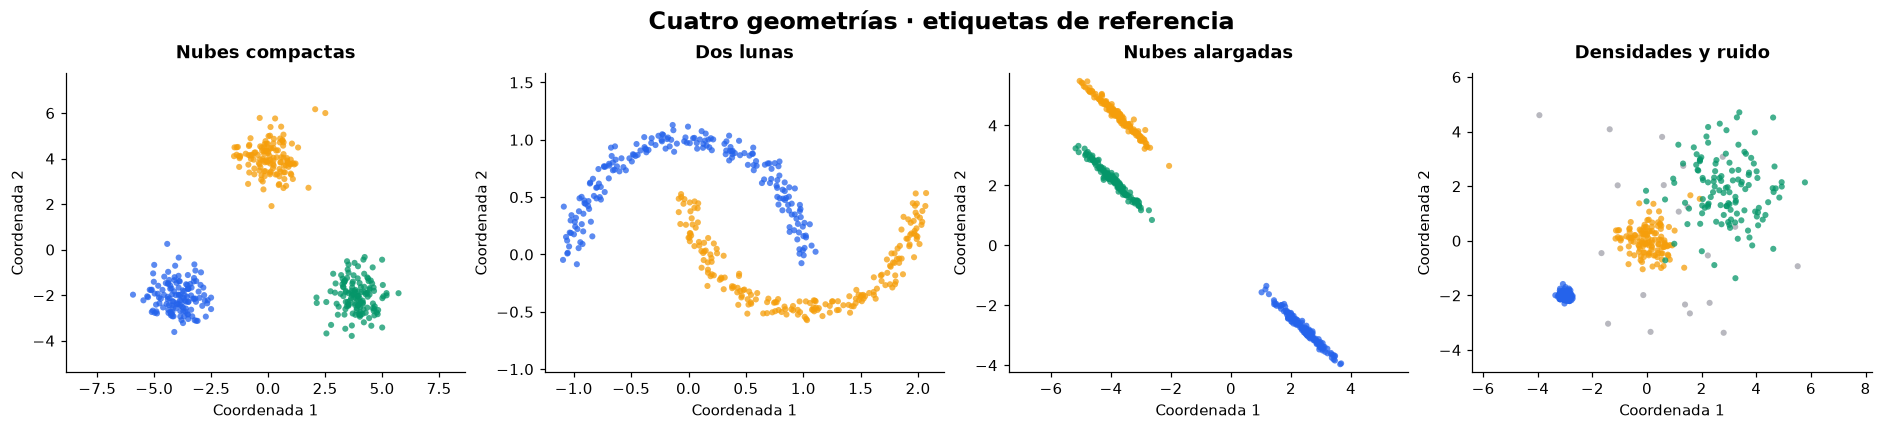

In [4]:
X_blobs, y_blobs = make_blobs(n_samples=400, centers=[(-4,-2),(0,4),(4,-2)],
                              cluster_std=.65, random_state=seed)
X_moons, y_moons = make_moons(n_samples=400, noise=.055, random_state=seed)
X_aniso, y_aniso = make_blobs(n_samples=400, centers=3, cluster_std=.65, random_state=seed)
X_aniso = X_aniso @ np.array([[.7, -.6], [-.4, .5]])
X_density, y_density = make_blobs(n_samples=[130,130,120],
    centers=[(-3,-2),(0,0),(3,2)], cluster_std=[.12,.5,1.05], random_state=seed)
X_density = np.vstack([X_density, rng.uniform([-5,-4],[6,5], size=(20,2))])
y_density = np.r_[y_density, np.full(20, -1)]
synthetic = {'Nubes compactas': (X_blobs,y_blobs), 'Dos lunas': (X_moons,y_moons),
             'Nubes alargadas': (X_aniso,y_aniso), 'Densidades y ruido': (X_density,y_density)}

fig, axes = plt.subplots(1,4,figsize=(17,3.8), layout='constrained')
for ax, (name,(X,y)) in zip(axes, synthetic.items()):
    plot_groups(ax,X,y,name)
    ax.set_aspect('equal', adjustable='datalim')
fig.suptitle('Cuatro geometrías · etiquetas de referencia', fontsize=16, fontweight='bold')
plt.show()


<div style="background-color:#EDF7FF;border:1px solid #7C9DBF;border-left:5px solid #7C9DBF;padding:.8em 1em;margin:1em 0;"><strong>Análisis:</strong> Completa la tabla de respuesta para los cuatro casos y K-means, DBSCAN, Ward y single linkage. Predice si, para cada dataset, el modelo es capaz de encontrar las componentes de la estructura, justifica cada fila con la dificultad del dataset. ¿Qué métodos obligan a indicar el número de grupos y cuáles pueden identificar ruido?</div>

| Caso | K-means | DBSCAN | Ward | Single linkage | Particularidad del dataset |
|---|---|---|---|---|---|
| Nubes compactas | Bien | Bien | Bien | Bien | Muy fácil: grupos de puntos con forma esférica, densidad uniforme y bien separados.|
| Dos lunas | Mal | Bien | Mal | Bien | Complicado: Los puntos hacen formas convexas y concavas.  |
| Nubes alargadas | Mal | Bien | Mal | Bien | Un poco complicado: Los puntos se agrupan en lineas, alta covarianza. |
| Densidades y ruido | Mal | Bien | Bien | Mal| Complicado: Cada grupo esta más disperso que el anterior, no hay una densidad uniforme y si muchos outliers. |

 
## 1.2 Elegir el número de grupos

Analiza y agrupa las siguientes **nubes compactas**. Este código proporcionado muestra los datos sin sus etiquetas de referencia.

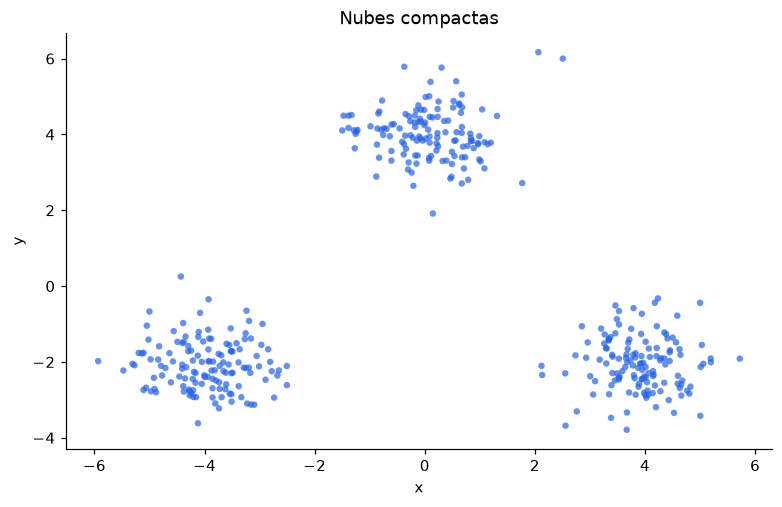

In [14]:
X_blobs, y_blobs = make_blobs(n_samples=400,centers=[(-4,-2),(0,4),(4,-2)], cluster_std=.65,random_state=seed)
fig,ax = plt.subplots(figsize=(7,4.5), layout='constrained')
ax.scatter(X_blobs[:,0], X_blobs[:,1], s=18, color=COLORS[0], alpha=.7, edgecolors='none')
ax.set(title='Nubes compactas', xlabel='x', ylabel='y')
plt.show()


<div style="background-color:#EDF7FF;border:1px solid #7C9DBF;border-left:5px solid #7C9DBF;padding:.8em 1em;margin:1em 0;"><strong>Implementación:</strong> Sobre las nubes compactas, prueba <code>k=2,...,7</code>. Representa en tres subplots la inercia (SSE), el silhouette y el resultado de la agrupación en el dataset (elige un valor de <code>k</code>).</div>

In [15]:
# Bucle que obtiene las métricas para KMeans con diferentes k
k_values = range(2, 8)
inertias = []
silhouettes = []

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=seed, n_init=10)
    labels = kmeans.fit_predict(X_blobs)
    
    inertias.append(kmeans.inertia_)
    silhouettes.append(silhouette_score(X_blobs, labels))

# Sabemos de antemano que el número óptimo de clusters es 3, así que lo usamos para el clustering final
k_optimo = 3
kmeans_final = KMeans(n_clusters=k_optimo, random_state=seed, n_init=10)
labels_optimo = kmeans_final.fit_predict(X_blobs)
centroides = kmeans_final.cluster_centers_ # Represento tambien los centroides de los clusters en el scatter plot

Una vez obtenidas las metricas para cada k del rango pedido, procedo a representar los gráficos eligiendo el k=3 ya que es el óptimo como ya sabemos. En el último subplot he decidido añadir la representacion de los centroides ya que nos puede ser interesante en el resultado y es sencillo de añadir a la representación.

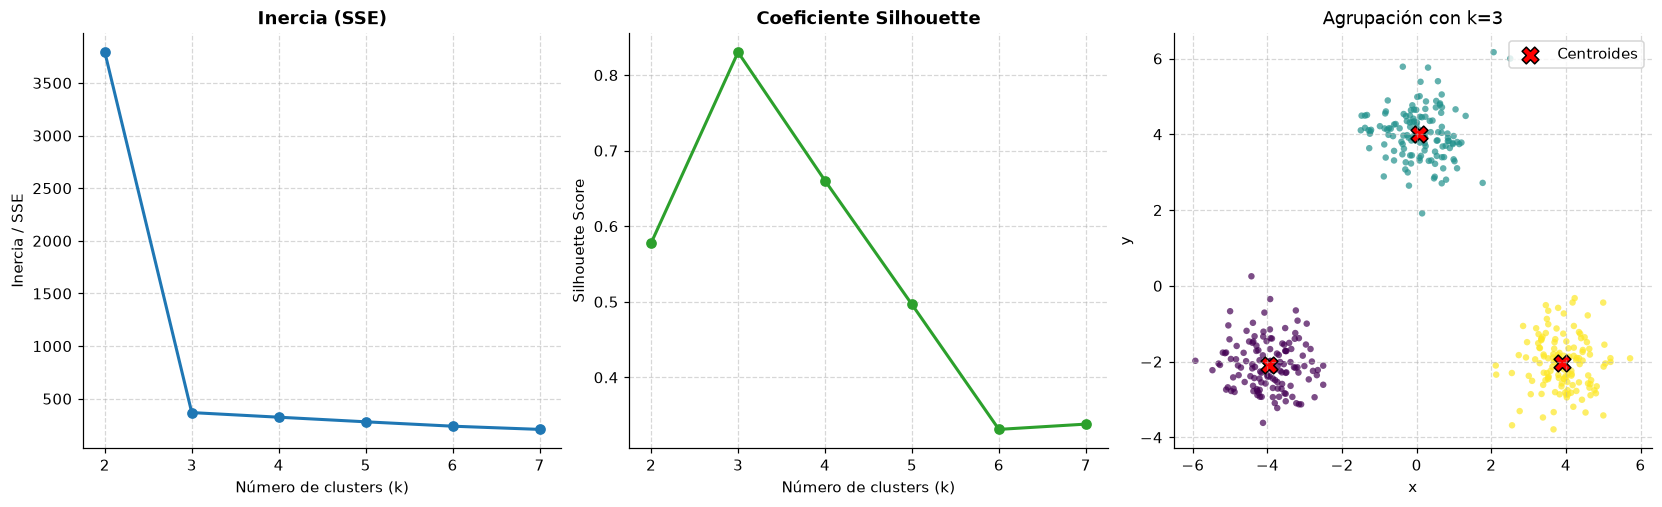

In [16]:
# Figura con tres subplots: Inercia, Coeficiente Silhouette y scatter plot clasificado
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 4.5), layout='constrained')

# Subplot 1: Inercia (SSE)
ax1.plot(k_values, inertias, marker='o', color='#1f77b4', linewidth=2)
ax1.set_title('Inercia (SSE)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Número de clusters (k)')
ax1.set_ylabel('Inercia / SSE')
ax1.grid(True, linestyle='--', alpha=0.5)

# Subplot 2: Coeficiente Silhouette
ax2.plot(k_values, silhouettes, marker='o', color='#2ca02c', linewidth=2)
ax2.set_title('Coeficiente Silhouette', fontsize=12, fontweight='bold')
ax2.set_xlabel('Número de clusters (k)')
ax2.set_ylabel('Silhouette Score')
ax2.grid(True, linestyle='--', alpha=0.5)

# Subplot 3: Visualización del clustering
ax3.scatter(*X_blobs.T, c=labels_optimo, cmap='viridis', s=18, alpha=0.7, edgecolors='none')
ax3.scatter(*centroides.T, marker='X', s=120, c='red', edgecolors='black', label='Centroides')
ax3.set(title=f'Agrupación con k={k_optimo}', xlabel='x', ylabel='y')
ax3.legend(loc='upper right')
ax3.grid(True, linestyle='--', alpha=0.5)

plt.show()

<div style="background-color:#EDF7FF;border:1px solid #7C9DBF;border-left:5px solid #7C9DBF;padding:.8em 1em;margin:1em 0;"><strong>Análisis:</strong> Interpreta las curvas del punto anterior. ¿Por qué la SSE siempre puede mejorar al aumentar <code>k</code>? ¿Un silhouette alto asegura que los grupos coinciden con el significado que buscamos?</div>

Si empezamos por el gráfico de la inercia vemos como el "codo" de la curva ocurre en k=3 al igual que el máximo del gráfico silhouette, indicandonos cómo ya sabíamos que el número óptimo de clusters a utilizar es 3 y podemos verlo en el scatter plot final con la clasificación por color de los clusters.

Observando el gráfico de la inercia vemos como el SSE se reduce a la vez que aumenta el k, esto se debe al sobreajuste ya que con más centroides la distancia entre cualquier punto y su centroide es menor. Esta manera de pensar termina por clasificar cada punto como su propio centroide para asi reducir por completo el error (lo cual es incorrecto). 

En el caso del gráfico silhouette vemos como su máximo se encuentra en k=3 esto se debe a que su valor aumenta con la calidad de la agrupación, es decir, cuanto más cohesión haya dentro de un grupo y más separación entre grupos su valor aumentará. Lo cual no quiere decir que esa buena separación geometrica tenga por qué coincidir con el significado buscado, sólo se centra en la calidad matemática de la separación de los grupos.

 
## 1.3 Comparar cuatro estrategias

Utiliza K-means, DBSCAN y aglomerativo (con enlaces Ward y single). Como K-means y el aglomerativo requieren el número de clusters, usa tres grupos, excepto en las lunas, ahí selecciona dos. Para DBSCAN prueba como máximo seis valores de `eps` por dataset y fija `min_samples=5`. Justifica tu elección mediante las vecindades y los gráficos.

Para entender si las estructuras descubiertas por los algoritmos se corresponden con las esperadas usaremos el **[ARI](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.adjusted_rand_score.html) (*Adjusted Rand Index*)**, que mide la coincidencia entre dos particiones (los grupos encontrados y las etiquetas del dataset).

Incluye todos los puntos al calcularlo e indica el porcentaje de ruido (eliminarlo podría ocultar fallos).

<div style="background-color:#EDF7FF;border:1px solid #7C9DBF;border-left:5px solid #7C9DBF;padding:.8em 1em;margin:1em 0;"><strong>Implementación:</strong> Vamos a implementar la tabla del apartado 1.1. Ajusta cada dataset con los 4 métodos y construye una figura de 4 × 4 subplots (datasets × algoritmos) para visualizarlo, una tabla con número de grupos, porcentaje de ruido y ARI, y un mapa de calor de ARI. Indica los parámetros elegidos en los modelos.</div>

Para encontrar los valores del parámetro "eps" óptimos primero selecciono una serie de 6 candidatos para cada conjunto y con estos creo diferentes tablas con los resultados que me ofrecen en cada conjunto. Lo que observo es el número de grupos que se detectan, el porcentaje de ruido y el ARI. Mi criterio para identificar los mejores parámetros será el que minimice el porcentaje de error y maximice el ARI (Adjusted Rand Index) que se usa para medir la calidad de un agrupamiento comparandolo a la realidad (esos casos suelen identificar el número de grupos correctos).

In [67]:
# 1. Definición de los 6 candidatos de eps por conjunto
eps_candidates = {
    'Nubes compactas':    [0.4, 0.5, 0.6, 0.7, 0.8, 0.9],
    'Dos lunas':          [0.08, 0.1, 0.12, 0.13, 0.15, 0.20],
    'Nubes alargadas':    [0.15, 0.2, 0.25, 0.3, 0.4, 0.5],
    'Densidades y ruido': [0.2, 0.3, 0.4, 0.5, 0.55, 0.6]
}

# 2. Evaluación de los 6 candidatos según nº de grupos,  % ruido y ARI
results = []
for dname, (X, y_true) in synthetic.items():
    for eps in eps_candidates[dname]:
        labels = DBSCAN(eps=eps, min_samples=5).fit_predict(X)
        n_groups = len(set(labels) - {-1})
        pct_noise = np.mean(labels == -1) * 100
        ari = adjusted_rand_score(y_true, labels)
        
        results.append({
            'Dataset': dname,
            'eps': eps,
            'Grupos': n_groups,
            '% Ruido': round(pct_noise, 1),
            'ARI': round(ari, 3)
        })

df_eps = pd.DataFrame(results)

# Mostramos la tabla comparativa, más efectivo que hacer representaciones gráficas de cada eps
for dname in synthetic:
    print(f"\n--- {dname.upper()} (Elegir el eps con grupos correctos y mayor ARI) ---")
    print(df_eps[df_eps['Dataset'] == dname][['eps', 'Grupos', '% Ruido', 'ARI']].to_string(index=False))

# Parametros óptimos seleccionados para el DBSCAN en cada conjunto
best_eps = {
    'Nubes compactas': 0.9,
    'Dos lunas': 0.13,
    'Nubes alargadas': 0.40,
    'Densidades y ruido': 0.50
}


--- NUBES COMPACTAS (Elegir el eps con grupos correctos y mayor ARI) ---
 eps  Grupos  % Ruido   ARI
 0.4       4      7.8 0.864
 0.5       3      4.8 0.927
 0.6       3      1.8 0.974
 0.7       3      1.5 0.978
 0.8       3      0.8 0.989
 0.9       3      0.5 0.993

--- DOS LUNAS (Elegir el eps con grupos correctos y mayor ARI) ---
 eps  Grupos  % Ruido   ARI
0.08      11      7.0 0.193
0.10       4      1.8 0.501
0.12       2      0.2 0.995
0.13       2      0.0 1.000
0.15       2      0.0 1.000
0.20       2      0.0 1.000

--- NUBES ALARGADAS (Elegir el eps con grupos correctos y mayor ARI) ---
 eps  Grupos  % Ruido   ARI
0.15       4      5.0 0.894
0.20       3      3.2 0.951
0.25       3      1.8 0.974
0.30       3      0.5 0.992
0.40       3      0.2 0.996
0.50       3      0.2 0.996

--- DENSIDADES Y RUIDO (Elegir el eps con grupos correctos y mayor ARI) ---
 eps  Grupos  % Ruido   ARI
0.20       5     39.5 0.682
0.30       9     20.5 0.751
0.40       7     11.5 0.813
0.50   

Para visualizar los valores elegidos utilizo los gráficos de vecinidad (k-NN) que ordenan los puntos según la distancia a su k-ésimo vecino para mostrar la densidad del dataset. El punto donde la curva se dispara hacia arriba (el "codo") marca el radio eps ideal para separar clusters densos de puntos aislados. En nuestro caso represento los valores elegidos en linea discontinua para analizar si quedan en el "codo" de la gráfica.

La mayorían quedan relativamente cerca, no quedan en un punto exacto porque he probado los valores del codo exacto y no me dan buenos resultados en el clustering por ello algunos valores estan algo por encima del codo para conseguir un mejor agrupamiento.

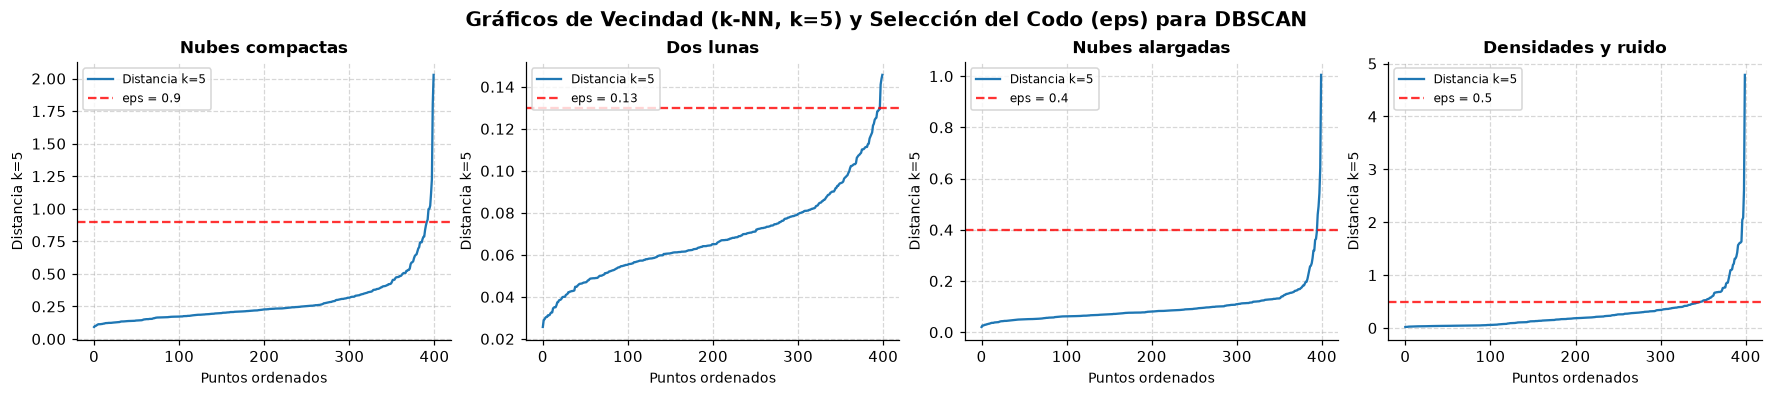

In [64]:
# Creación de la figura 1x4 para los gráficos de vecindad (k-NN)
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), layout='constrained')

for ax, (name, (X, _)) in zip(axes, synthetic.items()):
    # Calculamos la distancia al 5º vecino más cercano (k=5)
    nbrs = NearestNeighbors(n_neighbors=5).fit(X)
    dist = np.sort(nbrs.kneighbors(X)[0][:, 4])  # Distancia ordenada
    
    # Dibujamos la curva de vecindad
    ax.plot(dist, linewidth=1.5, label='Distancia k=5')
    
    # Línea horizontal indicando el eps elegido
    eps_val = best_eps[name]
    ax.axhline(y=eps_val, color='r', linestyle='--', alpha=0.8, label=f'eps = {eps_val}')
    
    # Formato y estilo del subgráfico
    ax.set_title(name, fontweight='bold', fontsize=11)
    ax.set_xlabel('Puntos ordenados', fontsize=9)
    ax.set_ylabel('Distancia k=5', fontsize=9)
    ax.grid(True, ls='--', alpha=0.5)
    ax.legend(loc='upper left', fontsize=8)

plt.suptitle('Gráficos de Vecindad (k-NN, k=5) y Selección del Codo (eps) para DBSCAN', fontweight='bold', fontsize=13)
plt.show()

Aquí podemos ver como utilizando los parametros del codo aproximadamente, no se obtienen buenos resultados. Vemos como no llega a clasificar bien el conjunto 3 en el de densidades y ruido. En el de dos lunas clasifica muchos más grupos de los que hay.

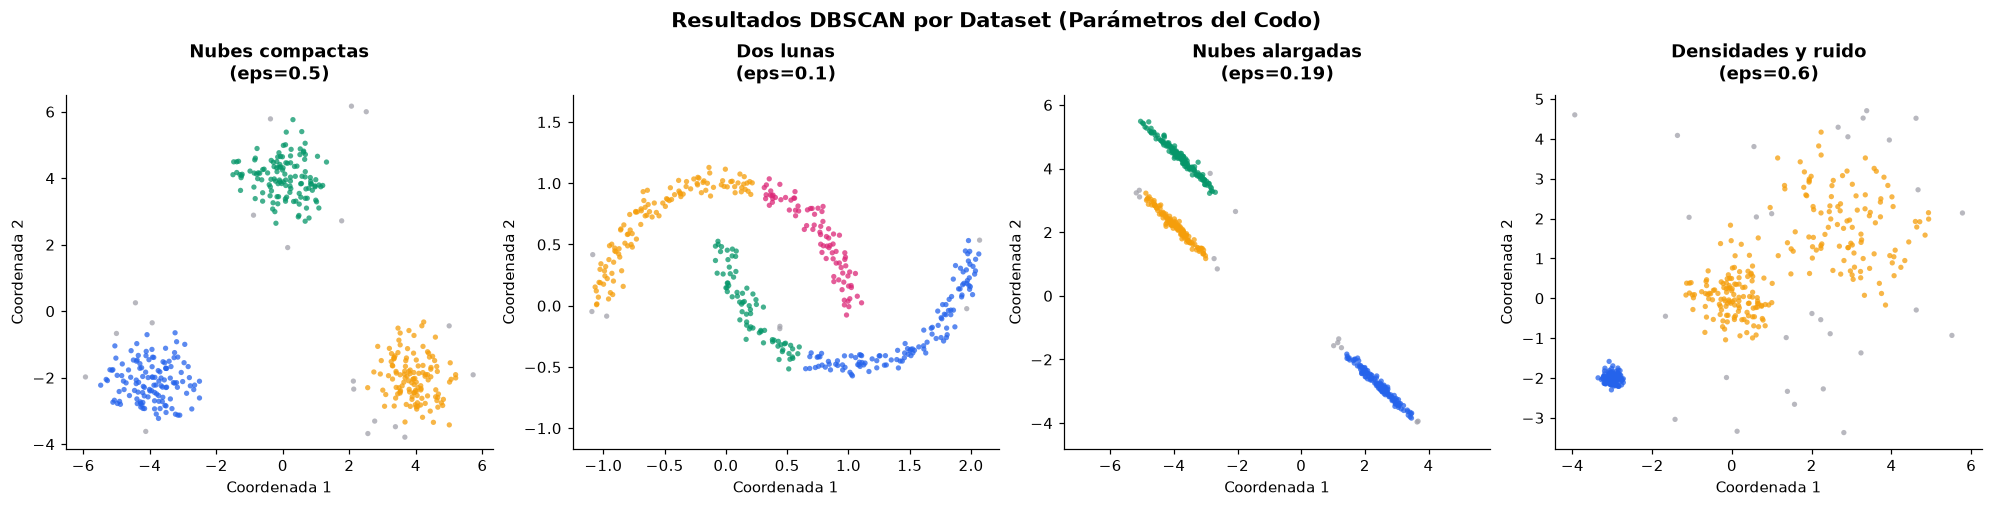

In [71]:
# Parámetros eps seleccionados a partir del codo (k=5)
best_eps_codo = {
    'Nubes compactas': 0.5,
    'Dos lunas': 0.1,
    'Nubes alargadas': 0.19,
    'Densidades y ruido': 0.6
}

# Configuración horizontal: 1 fila × 4 columnas
fig, axes = plt.subplots(1, len(synthetic), figsize=(18, 4.5), layout='constrained')

for col_idx, (dname, (X, y_true)) in enumerate(synthetic.items()):
    ax = axes[col_idx]
    
    # Ajustar DBSCAN
    dbscan = DBSCAN(eps=best_eps_codo[dname], min_samples=5)
    labels = dbscan.fit_predict(X)
    
    # Graficar resultados
    title_str = f"{dname}\n(eps={best_eps_codo[dname]})"
    plot_groups(ax, X, labels, title=title_str, size=12)
    ax.set_aspect('equal', adjustable='datalim')

fig.suptitle('Resultados DBSCAN por Dataset (Parámetros del Codo)', fontweight='bold', fontsize=14)
plt.show()

Procedo a realizar la figura con los 4x4 gráficos con cada clasificación hecha por cada método en cada conjunto. Podemos comprobar como efectivamente para el DBSCAN el parámetro "eps" es muy importante y como los óptimos que he seleccionado efectivamente actuan mejor a la hora de clasificar los grupos de cada conjunto de datos.

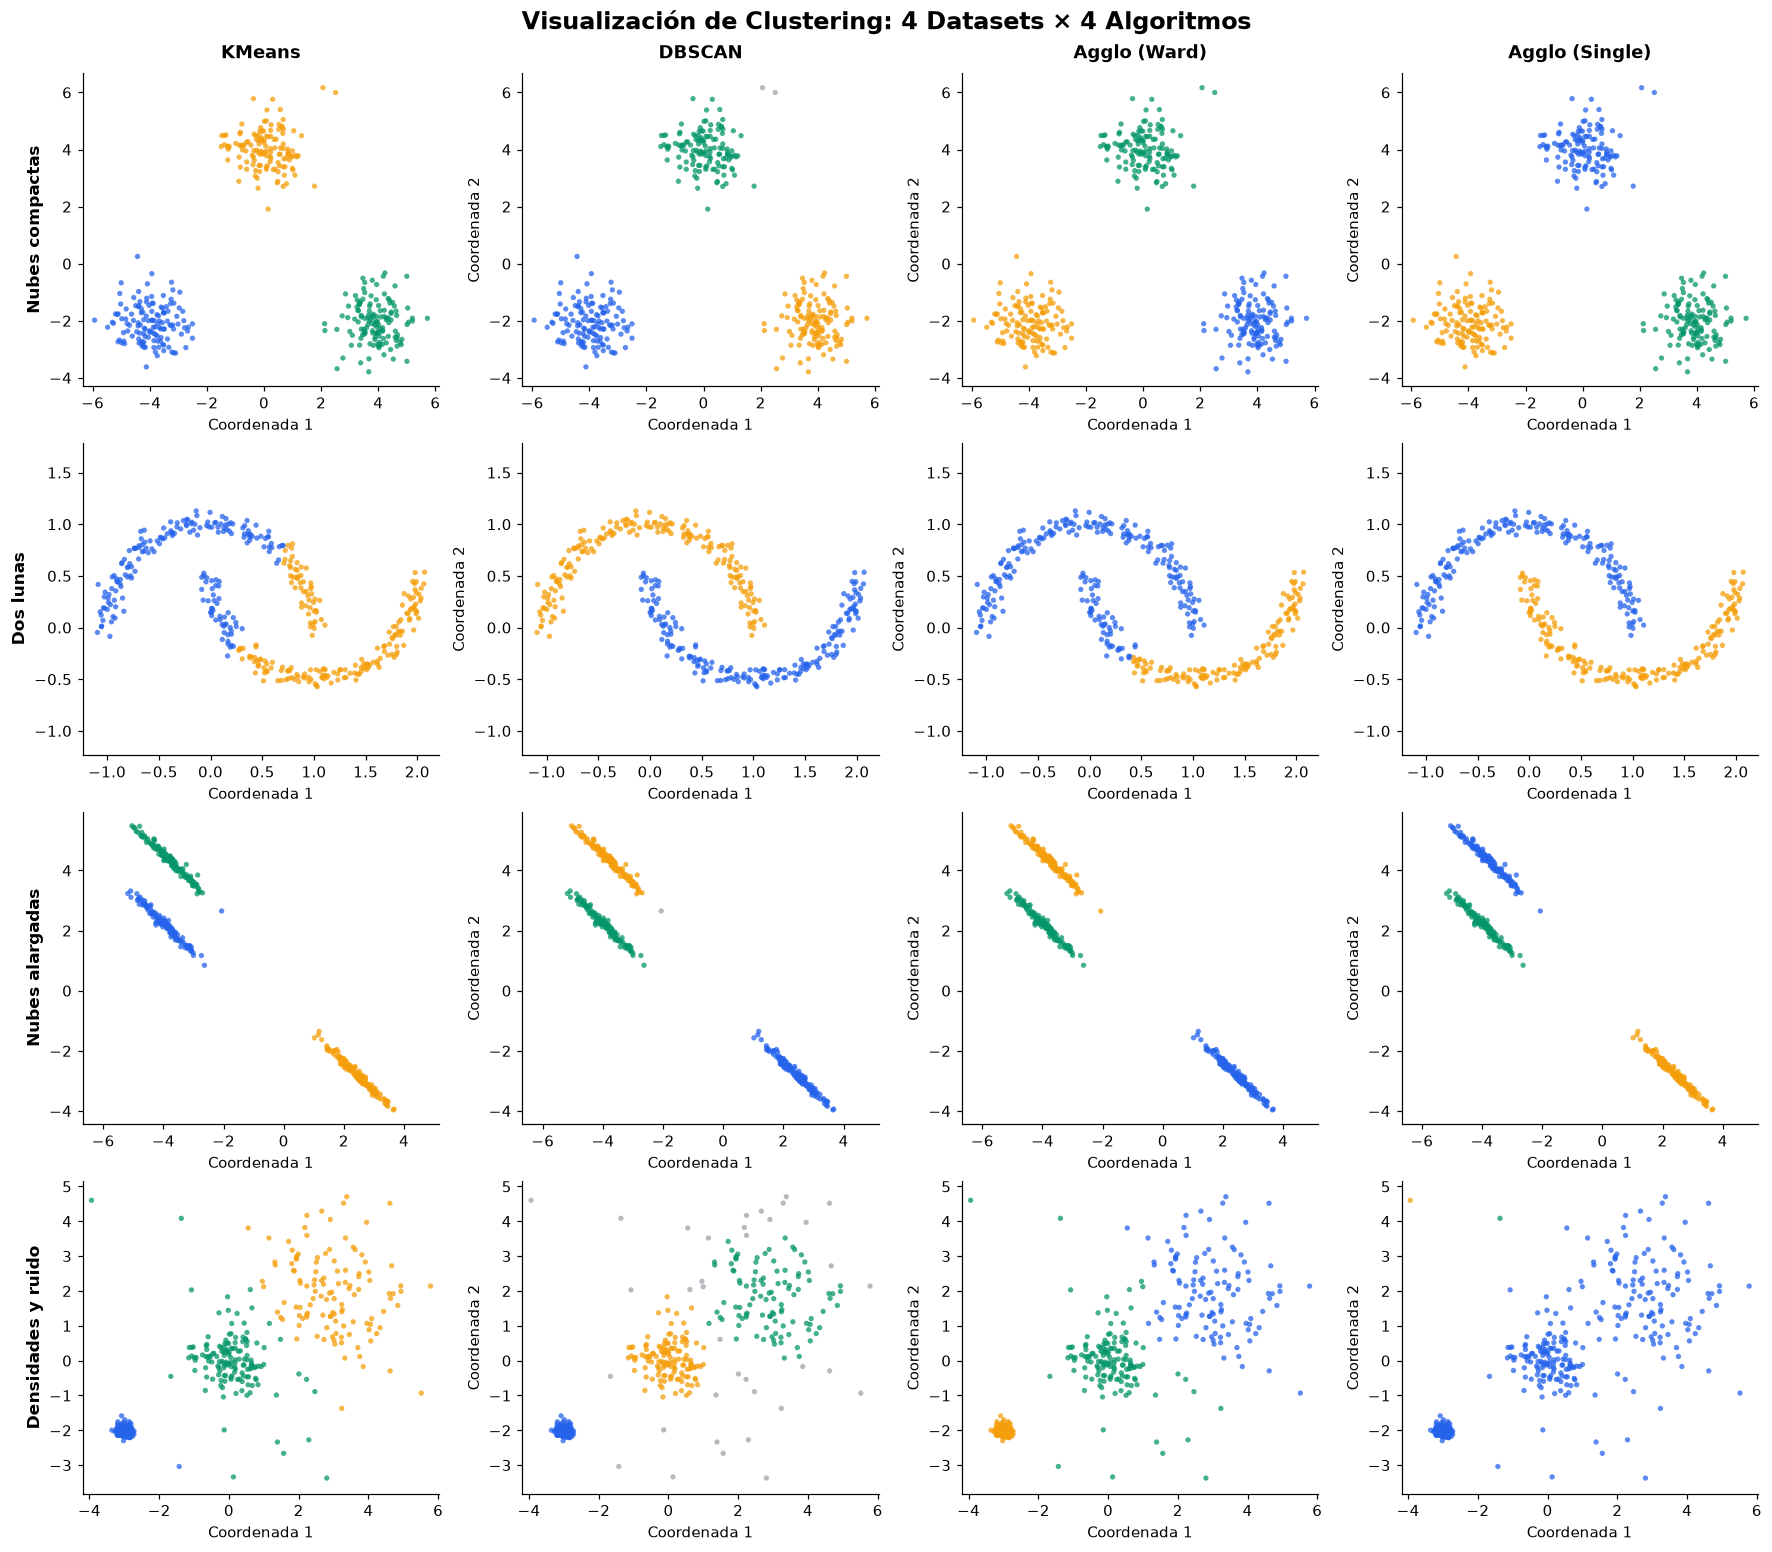

In [ ]:
# Ajuste de los 4 métodos de clustering
algos = ['KMeans', 'DBSCAN', 'Agglo (Ward)', 'Agglo (Single)']

fig, axes = plt.subplots(4, 4, figsize=(16, 14), layout='constrained')
metrics = []

# Bucle principal 4x4 
for row_idx, (dname, (X, y_true)) in enumerate(synthetic.items()):

    #Parámetros utilizados en los modelos
    k = 2 if dname == 'Dos lunas' else 3 # Cambio acorde al conjunto, ya que Dos lunas tiene 2 grupos y los demás 3
    models = {
        'KMeans': KMeans(n_clusters=k, random_state=seed, n_init=10),
        'DBSCAN': DBSCAN(eps=best_eps[dname], min_samples=5),
        'Agglo (Ward)': AgglomerativeClustering(n_clusters=k, linkage='ward'),
        'Agglo (Single)': AgglomerativeClustering(n_clusters=k, linkage='single')
    }
    
    for col_idx, mname in enumerate(algos):
        ax = axes[row_idx, col_idx]
        labels = models[mname].fit_predict(X)
        
        # Métricas pedidas para la tabla (calculadas sobre TODOS los puntos)
        n_groups = len(set(labels) - {-1}) #nº grupos
        pct_noise = np.mean(labels == -1) * 100 #% ruido
        ari = adjusted_rand_score(y_true, labels) #ARI
        
        metrics.append({
            'Dataset': dname, 'Algoritmo': mname,
            'Grupos': n_groups, '% Ruido': round(pct_noise, 1), 'ARI': round(ari, 3)
        })
        
        # Dibuja la agrupación usando la función predefinida plot_groups
        title_str = f"{mname}" if row_idx == 0 else ""
        plot_groups(ax, X, labels, title=title_str, size=12)
        ax.set_aspect('equal', adjustable='datalim')
        
        if col_idx == 0:
            ax.set_ylabel(dname, fontweight='bold', fontsize=11)

fig.suptitle('Visualización de Clustering: 4 Datasets × 4 Algoritmos', fontweight='bold', fontsize=16)
plt.show()

Ahora represento la tabla con las métricas pedidas:

In [53]:
# Tabla con nº de grupos, % ruido y ARI
df_metrics = pd.DataFrame(metrics)
print("\n--- TABLA DE MÉTRICAS ---")
print(df_metrics.to_string(index=False))


--- TABLA DE MÉTRICAS ---
           Dataset      Algoritmo  Grupos  % Ruido   ARI
   Nubes compactas         KMeans       3      0.0 1.000
   Nubes compactas         DBSCAN       3      0.5 0.993
   Nubes compactas   Agglo (Ward)       3      0.0 1.000
   Nubes compactas Agglo (Single)       3      0.0 1.000
         Dos lunas         KMeans       2      0.0 0.238
         Dos lunas         DBSCAN       2      0.0 1.000
         Dos lunas   Agglo (Ward)       2      0.0 0.496
         Dos lunas Agglo (Single)       2      0.0 1.000
   Nubes alargadas         KMeans       3      0.0 0.993
   Nubes alargadas         DBSCAN       3      0.2 0.996
   Nubes alargadas   Agglo (Ward)       3      0.0 1.000
   Nubes alargadas Agglo (Single)       3      0.0 1.000
Densidades y ruido         KMeans       3      0.0 0.853
Densidades y ruido         DBSCAN       3      9.0 0.862
Densidades y ruido   Agglo (Ward)       3      0.0 0.841
Densidades y ruido Agglo (Single)       3      0.0 0.007


Y finalmente represento el heatmap pedido para cada conjunto de datos y método. Comprobamos como efectivamente los más fáciles de clasificar son los que todos los métodos alcancen un ARI=1 (Nubes alargadas y nubes compactas). Y como el DBSCAN con buena elección de parámetros consigue adaptarse mejor a todos los conjuntos que el resto de métodos.

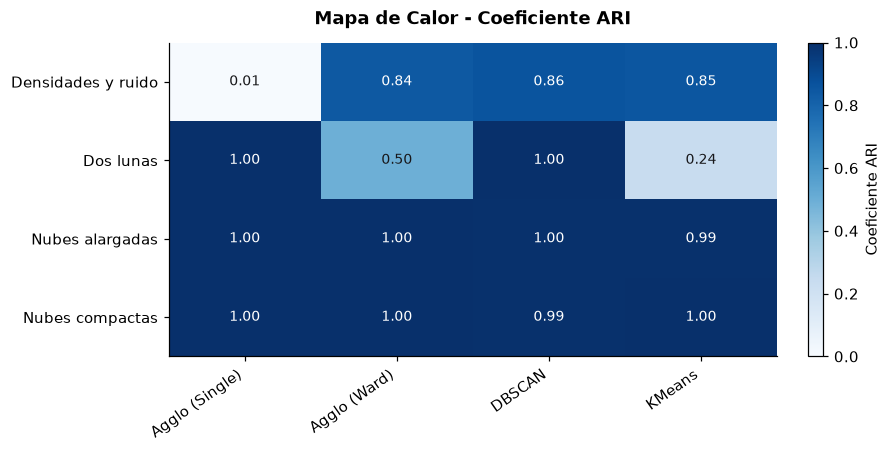

In [54]:
# Heatmap de ARI usando la función predefinida heatmap
pivot_ari = df_metrics.pivot(index='Dataset', columns='Algoritmo', values='ARI')

fig, ax = plt.subplots(figsize=(8, 4), layout='constrained')
im = heatmap(ax, pivot_ari.values, rows=pivot_ari.index, columns=pivot_ari.columns, 
            title='Mapa de Calor - Coeficiente ARI', cmap='Blues', vmin=0, vmax=1)
fig.colorbar(im, ax=ax, label='Coeficiente ARI')
plt.show()

<div style="background-color:#EDF7FF;border:1px solid #7C9DBF;border-left:5px solid #7C9DBF;padding:.8em 1em;margin:1em 0;"><strong>Análisis:</strong> ¿Coincide con tus predicciones? </div>

Corrijo las predicciones que había hecho:
| Caso | K-means | DBSCAN | Ward | Single linkage | Particularidad del dataset |
|---|---|---|---|---|---|
| Nubes compactas | Bien | Bien | Bien | Bien | Muy fácil: grupos de puntos con forma esférica, densidad uniforme y bien separados.|
| Dos lunas | Mal | Bien | Mal | Bien | Complicado: Los puntos hacen formas convexas y concavas.  |
| Nubes alargadas | **Bien** ~~Mal~~ | Bien | **Bien** ~~Mal~~ | Bien | Poco complicado: Los puntos se agrupan en lineas, alta covarianza. |
| Densidades y ruido | **Bien** ~~Mal~~ | Bien | Bien | Mal| Complicado: Cada grupo esta más disperso que el anterior, no hay una densidad uniforme y si muchos outliers. |

Resulta que me equivoqué en el conjunto de nubes alargadas dado que todos los métodos consiguen clasificarlo bien. En densidades y ruido también ya que el K-means si logró clasificar bien los grupos. En cuanto a los demás conjuntos y métodos si conseguí acertar mi predicción, incluso en la dificultad, siendo lo más dificiles de clasificar los conjuntos que etiqueto como "complicado" ya que como vemos en el heatmap, menos métodos son capaces de conseguir un ARI cercano a 1.

 
## 1.4 La diferencia entre Ward y Single

<div style="background-color:#EDF7FF;border:1px solid #7C9DBF;border-left:5px solid #7C9DBF;padding:.8em 1em;margin:1em 0;"><strong>Implementación:</strong> En el dataset de las lunas, representa dendrogramas con enlaces Ward y single sobre una submuestra (la misma para ambos métodos) de 80 puntos. En el dataset de densidades, representa en otros dos subplots cómo varía el número de grupos y el porcentaje de ruido con valores de <code>eps de {0.10, 0.20, 0.35, 0.50, 0.80, 1.20}</code>.</div>

Represento los dos dendogramas de la submuestra de puntos, cada uno con un tipo diferente de enlace. Se aprecia que con Wald sólo hay dos grupos principales en cambio con single hay, es evidente que tienen una representación de dendogramas distinta y las distancias son distintas también.

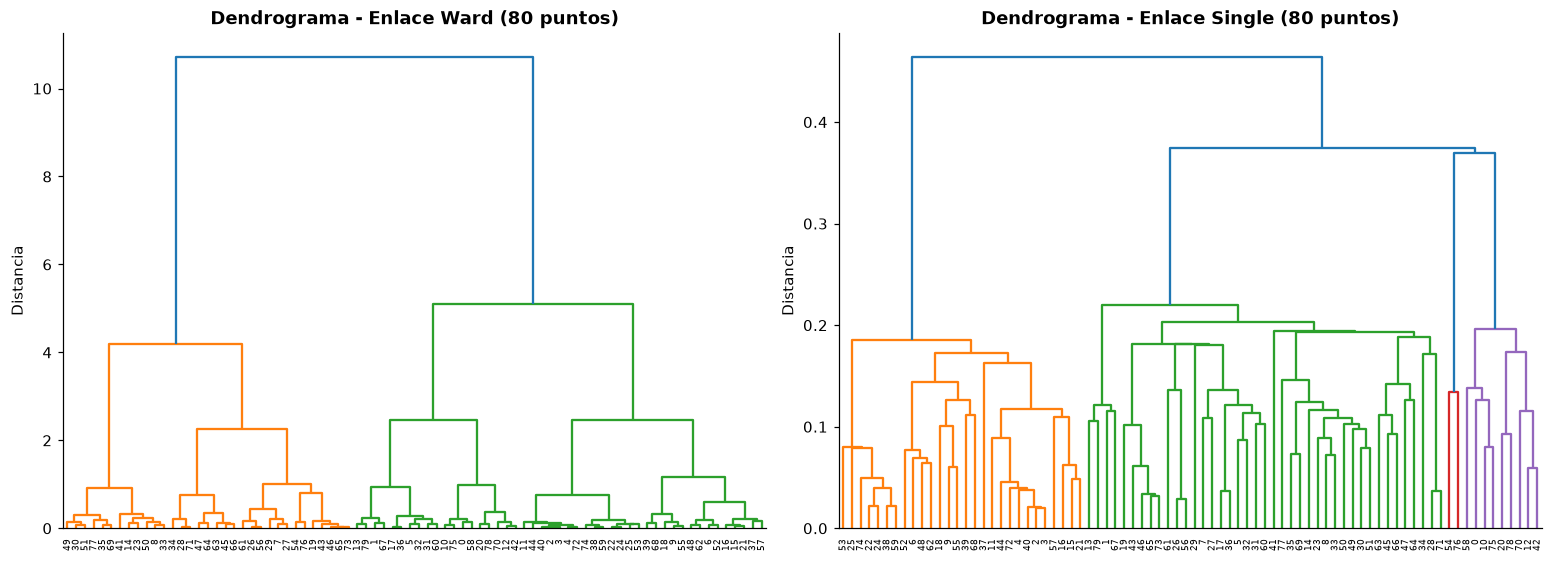

In [ ]:
# -----------------------------------------------------------------------------
# PARTE 1: Dendrogramas ('Dos lunas' - Submuestra de 80 puntos)
# -----------------------------------------------------------------------------
X_lunas, _ = synthetic['Dos lunas']

# Selección de la misma submuestra de 80 puntos para ambos métodos
indices = np.random.choice(X_lunas.shape[0], size=80, replace=False)
X_lunas_sub = X_lunas[indices]

# Matriz de enlaces (Linkage matrix)
Z_ward = linkage(X_lunas_sub, method='ward')
Z_single = linkage(X_lunas_sub, method='single')

fig1, axes1 = plt.subplots(1, 2, figsize=(14, 5), layout='constrained')

dendrogram(Z_ward, ax=axes1[0])
axes1[0].set_title('Dendrograma - Enlace Ward (80 puntos)', fontweight='bold')
axes1[0].set_ylabel('Distancia')

dendrogram(Z_single, ax=axes1[1])
axes1[1].set_title('Dendrograma - Enlace Single (80 puntos)', fontweight='bold')
axes1[1].set_ylabel('Distancia')

plt.show()

Ahora represento las dos figuras para comparar eps contra el número de grupos y el porcentaje de ruido respectivamente. Vemos como ambos disminuyen a la vez que aumenta el eps.

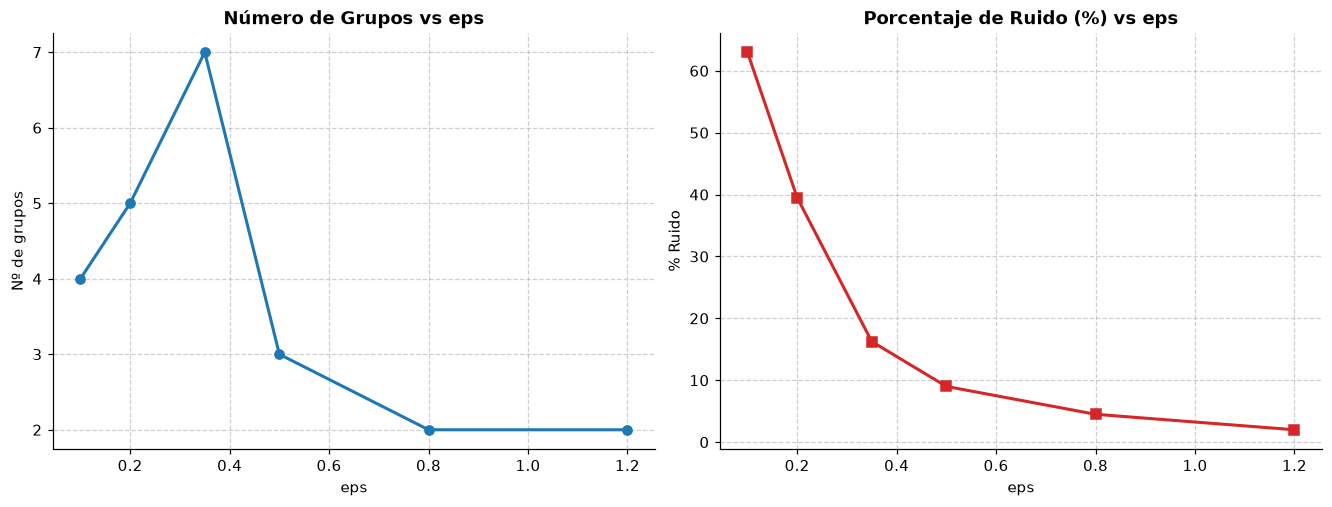

In [ ]:
# -----------------------------------------------------------------------------
# PARTE 2: Sensibilidad de DBSCAN ('Densidades y ruido')
# -----------------------------------------------------------------------------
X_dens, _ = synthetic['Densidades y ruido']
eps_values = [0.10, 0.20, 0.35, 0.50, 0.80, 1.20]

n_groups_list = []
pct_noise_list = []

for eps in eps_values:
    db = DBSCAN(eps=eps, min_samples=5).fit(X_dens)
    labels = db.labels_
    
    # Nº de grupos (excluyendo el ruido -1)
    n_groups = len(set(labels) - {-1})
    # Porcentaje de puntos considerados ruido
    pct_noise = np.mean(labels == -1) * 100
    
    n_groups_list.append(n_groups)
    pct_noise_list.append(pct_noise)

fig2, axes2 = plt.subplots(1, 2, figsize=(12, 4.5), layout='constrained')

# Subplot 1: Número de grupos vs eps
axes2[0].plot(eps_values, n_groups_list, marker='o', color='tab:blue', linewidth=2)
axes2[0].set_title('Número de Grupos vs eps', fontweight='bold')
axes2[0].set_xlabel('eps')
axes2[0].set_ylabel('Nº de grupos')
axes2[0].grid(True, linestyle='--', alpha=0.6)

# Subplot 2: Porcentaje de ruido vs eps
axes2[1].plot(eps_values, pct_noise_list, marker='s', color='tab:red', linewidth=2)
axes2[1].set_title('Porcentaje de Ruido (%) vs eps', fontweight='bold')
axes2[1].set_xlabel('eps')
axes2[1].set_ylabel('% Ruido')
axes2[1].grid(True, linestyle='--', alpha=0.6)

plt.show()

<div style="background-color:#EDF7FF;border:1px solid #7C9DBF;border-left:5px solid #7C9DBF;padding:.8em 1em;margin:1em 0;"><strong>Análisis:</strong> ¿Por qué dos enlaces generan dendrogramas distintos? ¿Puede el número de grupos detectados por DBSCAN ser igual al esperado y, aun así, haber descartado gran parte de los datos?</div>

Dado que el agrupamiento jerárquico aglomerativo es un método voraz (greedy) que en cada paso fusiona iterativamente los dos grupos más cercanos, la forma en que se define la distancia entre clústeres altera por completo las decisiones de unión. Cada criterio de enlace define la distancia de una forma distinta (Single linkage usa la distancia mínima entre elementos, Complete linkage la distancia máxima y Ward minimiza la varianza intra-clúster). Esto modifica el orden de fusión y la altura de las ramas, generando una estructura de árbol y un dendrograma totalmente diferente.

Sí, el DBSCAN identifica clústeres basándose exclusivamente en la densidad local. Si los parámetros de vecindad (eps) o el número mínimo de puntos (minPts) están configurados de forma restrictiva, el algoritmo puede localizar exactamente el número de grupos densos esperado y, al mismo tiempo, clasificar una gran porción de los datos como ruido o outliers, descartandolos.


## 1.5 Feature engineering para agrupar datos

En el dataset de los dos círculos concéntricos empezaremos usando las coordenadas cartesianas `(x,y)`. Comprueba si conocer el número correcto de grupos basta para recuperar los dos círculos.

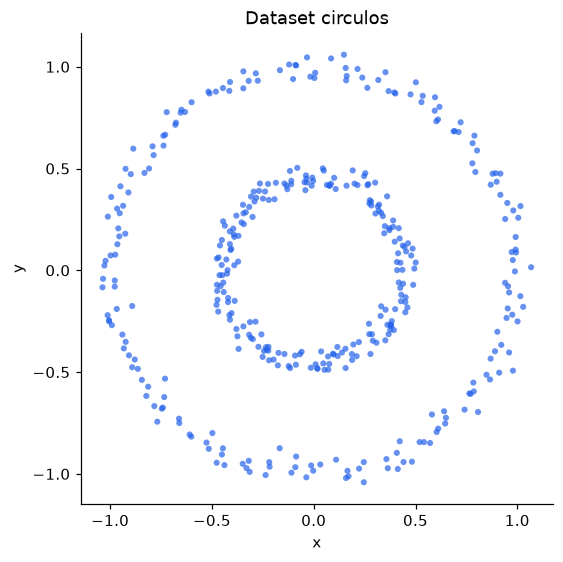

In [75]:
X_rings,y_rings = make_circles(n_samples=400, factor=.45, noise=.035, random_state=seed)
fig,ax = plt.subplots(figsize=(5.5,5), layout='constrained')
ax.scatter(X_rings[:,0], X_rings[:,1], s=16, color=COLORS[0], alpha=.7, edgecolors='none')
ax.set(title='Dataset circulos', xlabel='x', ylabel='y')
ax.set_aspect('equal')
plt.show()

<div style="background-color:#EDF7FF;border:1px solid #7C9DBF;border-left:5px solid #7C9DBF;padding:.8em 1em;margin:1em 0;"><strong>Implementación:</strong> Aplica K-means con <code>k=2</code> sobre las coordenadas originales. Representa los grupos y calcula ARI respecto a los dos círculos de referencia.</div>

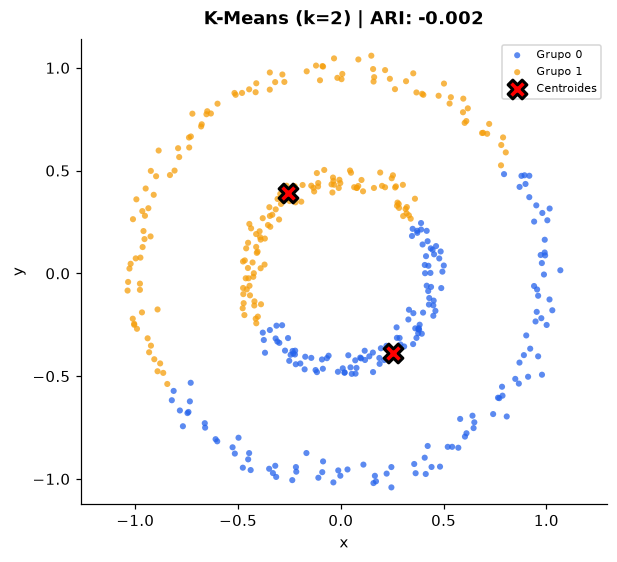

El valor de ARI para K-Means es: -0.002


In [80]:
# K-Means con k=2 sobre las coordenadas originales
kmeans = KMeans(n_clusters=2, random_state=seed, n_init=10)
labels_kmeans = kmeans.fit_predict(X_rings)

# Calculo la métrica ARI (Adjusted Rand Index)
ari_kmeans = adjusted_rand_score(y_rings, labels_kmeans)

# Representación gráfica de los grupos predichos
fig, ax = plt.subplots(figsize=(5.5, 5), layout='constrained')

plot_groups(ax, X_rings, labels_kmeans, title=f"K-Means (k=2) | ARI: {ari_kmeans:.3f}", size=16)

# Dibujo los centroides en la gráfica
centroids = kmeans.cluster_centers_
ax.scatter(centroids[:, 0], centroids[:, 1], color='red', marker='X', s=150, linewidths=2, edgecolor='black', label='Centroides', zorder=10)

ax.legend(loc='upper right',  fontsize=7)
ax.set(xlabel='x', ylabel='y')
ax.set_aspect('equal', adjustable='datalim')
plt.show()

print(f"El valor de ARI para K-Means es: {ari_kmeans:.3f}")

<div style="background-color:#EDF7FF;border:1px solid #7C9DBF;border-left:5px solid #7C9DBF;padding:.8em 1em;margin:1em 0;"><strong>Análisis:</strong> ¿Recupera K-means los dos círculos? Explica el fallo a partir de sus centroides y de la distancia euclídea. ¿Cómo intentarías solucionarlo? ¿Cambiarías de algoritmo? Propón una alternativa y justifícala antes de continuar.</div>

No, K-means es incapaz de separar correctamente la estructura de dos círculos concéntricos. Esto se debe a que la separación que hace es lineal dado que utiliza la distancia euclidea de los puntos a los centroides. Al no poder realizar esta separación lineal en los circulos concéntricos porque ambos compartirian mismos centroides lo que hace es dividir la figura asignando la mitad a cada uno en los centroides como vemos.

Para solucionarlo, se me ocurre sin necesidad de cambiar el algorítmo, simplemente cambiar el sistema de cordenadas a coordenadas polares para que así la representación de los puntos pueda ser separable linealmente en 2 grupos. Si no una alternativa al DBSCAN sería un agrupamiento jerarquico por enlace single (simple) lo cual al tomar las distancias mínimas identificaría sin problema los anillos ya que entre ellos hay suficiente separación para que no los clasifique a un mismo grupo.


### Transformación del dato

Vamos a mantener el algoritmo, pero transformando los datos.
El centro de generación conocido de estos círculos es `(0,0)`. Calcula una única feature: el **radio**. Es decir, la distancia de cada punto al origen:

$$r_i = \sqrt{x_i^2+y_i^2}.$$

Dos puntos en posiciones opuestas del mismo círculo están lejos en `(x,y)`, pero tienen radios parecidos.
Vamos a comprobar si esta feature permite separar los dos círculos usando la distancia al origen `(0,0)`.

<div style="background-color:#EDF7FF;border:1px solid #7C9DBF;border-left:5px solid #7C9DBF;padding:.8em 1em;margin:1em 0;"><strong>Implementación:</strong> Crea el nuevo dataset donde, para cada muestra, en lugar de representarla con x e y, sea su radio. Aplica K-means con <code>k=2</code> solo a la columna radio. Grafica el dataset original coloreando los puntos con el resultado de la agrupación de K-means sobre el dato inicial (x,y) con su ARI, también el dataset original pero coloreando las muestras con la agrupación por radio (la nueva feature) con su ARI, y los histogramas de la variable radio para cada una de las etiquetas originales.</div>

In [82]:
# Creo el nuevo dataset: cálculo del radio r = sqrt(x^2 + y^2)
r = np.sqrt(X_rings[:, 0]**2 + X_rings[:, 1]**2).reshape(-1, 1)

# Aplico K-Means con k=2 sobre el nuevo dataset
kmeans_r = KMeans(n_clusters=2, random_state=seed, n_init=10)
labels_r = kmeans_r.fit_predict(r)

# ARI sobre la variable radio (r)
ari_r = adjusted_rand_score(y_rings, labels_r) 

Después de haber hecho los calculos del nuevo dataset con el radio realizo los gráficos que se me piden. Como vemos la transformación del radio efectivamente nos ayuda a que K-means classifique correctamente los 2 grupos. Vemos como el ARI consecuente mente de ser nulo pasa a ser 1 (su máximo valor de calidad) con esta transformación.

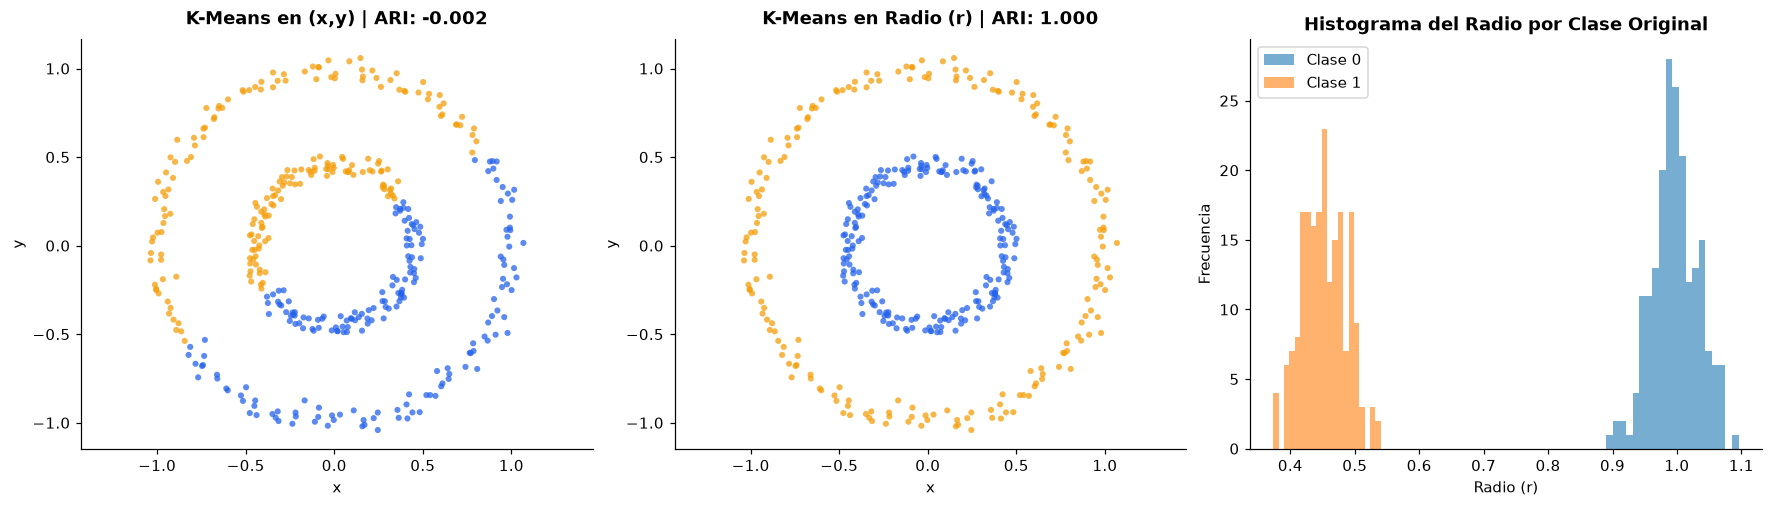

ARI en espacio (x,y): -0.002
ARI en espacio Radio (r): 1.000


In [83]:
# Representación gráfica: 3 subplots
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), layout='constrained')

# Subplot 1: Clustering en espacio original (x, y)
plot_groups(axes[0], X_rings, labels_kmeans, title=f"K-Means en (x,y) | ARI: {ari_kmeans:.3f}", size=16)
axes[0].set(xlabel='x', ylabel='y')
axes[0].set_aspect('equal', adjustable='datalim')

# Subplot 2: Clustering basado en la variable radio r
plot_groups(axes[1], X_rings, labels_r, title=f"K-Means en Radio (r) | ARI: {ari_r:.3f}", size=16)
axes[1].set(xlabel='x', ylabel='y')
axes[1].set_aspect('equal', adjustable='datalim')

# Subplot 3: Histograma del radio por clase original
for label in np.unique(y_rings):
    r_class = r[y_rings == label]
    axes[2].hist(r_class, bins=20, alpha=0.6, label=f'Clase {label}')

axes[2].set_title('Histograma del Radio por Clase Original', fontweight='bold')
axes[2].set_xlabel('Radio (r)')
axes[2].set_ylabel('Frecuencia')
axes[2].legend()

plt.show()

print(f"ARI en espacio (x,y): {ari_kmeans:.3f}")
print(f"ARI en espacio Radio (r): {ari_r:.3f}")

<div style="background-color:#EDF7FF;border:1px solid #7C9DBF;border-left:5px solid #7C9DBF;padding:.8em 1em;margin:1em 0;"><strong>Análisis:</strong> ¿Han cambiado las etiquetas encontradas? ¿Y el ARI? ¿Por qué?</div>

Efectivamente ha cambiado a una clasificación correcta, al igual que el ARI que alcanza su mayor valor con la transformación. Esto se debe a que con la transformación de las coordenadas al radio el espacio se vuelve linealmente separable (como vemos en el histograma) lo que nos permite hacer una correcta clasificación con K-means.


# 2. ¿Qué arreglamos en la próxima release? (6 puntos)

Trabajas con el equipo de calidad de un estudio de videojuegos. El equipo quiere entender qué **familias de problemas** están experimentando los usuarios para solventarlos, a partir de muchos comentarios escritos con vocabularios distintos. Los comentarios positivos también aportan contexto: no toda mención de rendimiento o dificultad es una queja.

En la primera parte agruparás por similitud general del texto con **MiniLM**. En la segunda, construirás nuevas features con **Laya**, un modelo de decisiones, y comprobarás si los grupos resultan más fáciles de interpretar para nuestro objetivo.

## Dataset: comentarios históricos de Steam

`steam_reviews_pec2.csv` contiene **2.000 comentarios reales distintos (en inglés) de doce videojuegos**, extraídos del corpus histórico
de Steam del grupo de Julian McAuley. Steam permite recomendar o no recomendar un juego y escribir un comentario libre.
Los comentarios combinan felicitaciones, críticas, humor, sarcasmo y varios problemas en un mismo comentario (con partes positivas y negativas).

Puedes consultar la [descripción del dataset Steam](https://cseweb.ucsd.edu/~jmcauley/datasets.html#steam_data)
y descargar el [archivo original](https://mcauleylab.ucsd.edu/public_datasets/data/steam/australian_user_reviews.json.gz).
Los [metadatos originales de juegos](https://cseweb.ucsd.edu/~wckang/steam_games.json.gz) se usan únicamente para añadir los títulos.

| Columna | Descripción y uso en la PEC |
|---|---|
| `review_id` | Identificador del comentario |
| `game_id`, `game` | Identificador del juego y título (para hacerlo interpretable) |
| `text` | Comentario original **será la entrada para MiniLM y Laya** |
| `recommend` | Recomendación original del autor |

## 2.1 Familiarizarnos con los comentarios

Campos: `review_id`, `game_id`, `game`, `text`, `recommend`. Utiliza solamente `text` como entrada de los modelos.
El nombre del juego y la recomendación se reservan para el análisis posterior, no son etiquetas del problema que queremos descubrir.

Puede que al procesar los comentarios tarde bastante tiempo, en la siguiente celda hemos dejado una constante *N_REVIEWS* que puedes disminuir para acelerar el proceso. Pero hará más difícil ver los resultados de los apartados.

In [84]:
raw = pd.read_csv(DATA/'steam_reviews_pec2.csv',dtype={'review_id':str,'game_id':str})
assert len(raw) == 2000

N_REVIEWS = 2000
print('Comentarios en el extracto:',len(raw))
display(raw[['review_id','game','text']].head(3))

Comentarios en el extracto: 2000


,review_id,game,text
0,S0000,Team Fortress 2,I enjoy playing dress-up with grown men.I enjoy killing dressed-up grown men.I enjoy dancing around on the battlefield with dressed-up grown men.I enjoy getting killed by dressed-up grown men.I enjoy wasting money to buy cosmetics for grown men.10/10 Would waste money again. :)
1,S0001,Loadout,"A game if you want to just shoot and shoot and not do much else. Yeah, 26 minutes was about all I could stand, obviously not my cup of tea."
2,S0002,Unturned,"Indeed a lot of fun. It can kinda be annoying that you can get killed so easily, but that could be just that i suck at the game xD. Buy it, it's really a lot of fun!"


<div style="background-color:#EDF7FF;border:1px solid #7C9DBF;border-left:5px solid #7C9DBF;padding:.8em 1em;margin:1em 0;"><strong>Implementación:</strong> Limpia vacíos y duplicados, utiliza los 2.000 comentarios o reduce <code>N_REVIEWS</code> a 1.000 si la ejecución es lenta. Usa la semilla común para que el muestreo sea reproducible. Guárdala como <code>reviews</code>. Representa en dos gráficas: la longitud de los textos y el número de comentarios por juego.</div>

In [ ]:
# Limpieza de vacíos y duplicados
cleaned_df = raw.dropna(subset=['review_id', 'game', 'text']).drop_duplicates(subset=['review_id'])

# Muestreo reproducible (utilizando N_REVIEWS y SEED)
SEED = 42
reviews = cleaned_df.sample(
    n=min(N_REVIEWS, len(cleaned_df)), # En caso de no haber 2000 comentarios únicos tomamos el mínimo
    random_state=SEED
).reset_index(drop=True) # soluciona problemas de indexación al eliminar duplicados

print(f'Comentarios finales en reviews: {len(reviews)}')

Comentarios finales en reviews: 2000


Comprobamos que efectivamente hay 2000 comentarios sin problemas después de la limpieza de NA's y duplicados. Procedo a realizar las dos representaciones la primera de longitud de textos en forma de histograma y la segunda de número de comentarios por juego en diagrama de barras horizontal.

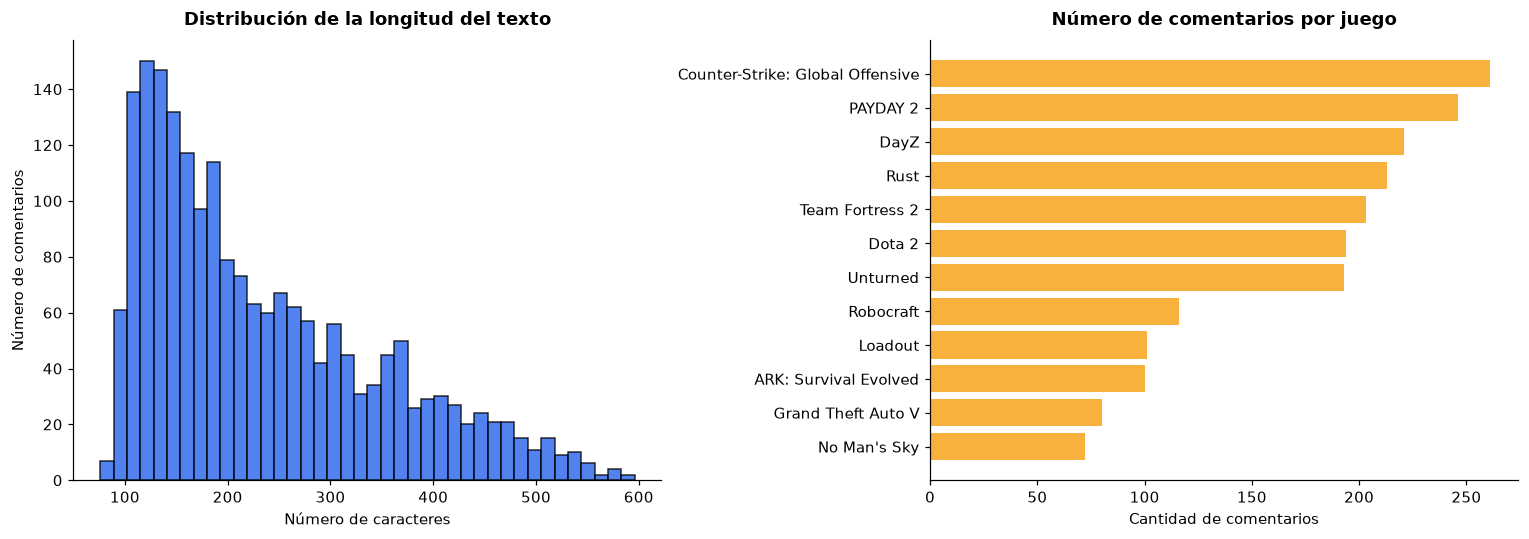

In [93]:
# Visualización de longitud de textos y distribución por juego
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Gráfica 1: Longitud de los textos (en caracteres)
text_lengths = reviews['text'].str.len()
ax1.hist(text_lengths, bins=40, color=COLORS[0], edgecolor='black', alpha=0.8)
ax1.set_title('Distribución de la longitud del texto', fontweight='bold', pad=10)
ax1.set_xlabel('Número de caracteres')
ax1.set_ylabel('Número de comentarios')

# Gráfica 2: Número de comentarios por juego
game_counts = reviews['game'].value_counts()
ax2.barh(game_counts.index, game_counts.values, color=COLORS[1], alpha=0.8)
ax2.set_title('Número de comentarios por juego', fontweight='bold', pad=10)
ax2.set_xlabel('Cantidad de comentarios')
ax2.invert_yaxis()  # Mostrar el juego con más comentarios arriba

plt.tight_layout()
plt.show()

<div style="background-color:#EDF7FF;border:1px solid #7C9DBF;border-left:5px solid #7C9DBF;padding:.8em 1em;margin:1em 0;"><strong>Análisis:</strong> Lee cinco comentarios. ¿Qué ambigüedades encuentras?</div>

Tras leer los 5 primeros del dataset he encontrado diferencias en la forma de expresarse muy evidentes, como ironía en el comentario de "No Man's Sky". Lo mismo con el de "Team Fortress 2" que incluye bromas y formas de expresarse como "LOL" que sólo se usan dentro de internet. En general una conjunto de datos muy heterogeneo para ser interpretado de forma correcta, no se sigue una estructura y cada uno comenta una cosa (puede que incluso no se mencione apenas el juego si es bueno o no como en el comentario de "Unturned").

In [95]:
display(reviews[['review_id', 'game', 'text']].head(5))

,review_id,game,text
0,S1860,Unturned,"Singleplayer: Own every item in the game, have a base that stretches around 10% of the entire map, reign supreme over the zombies of the land with an impressive armoury of many weapons.Multiplayer: Spawn and get shot8/8 'Gr8 B8 M8'"
1,S0353,No Man's Sky,- Mediocre space game - Hard to control Starship with Mouse + Keyboard- Bored after 5+ hrs- No beach or forests biome but rocks and caves and ♥♥♥♥♥- No Multiplayer- Liar Developers- Peasant Station 4 ported - Not worth for 60$7/11meme
2,S1333,Team Fortress 2,"lol gud gam 420swag but still not as good as your mom LOL XD!!111!, huge shoutout to my mentor xX[UT]{O.W.N}RAWR|;; SwagKing69#road2swagXx for teaching me about this wonderful game"
3,S0905,Robocraft,"Great Game, Classic Vehicle Combat (Tanks or Jets) mixed with Minecraft (Build whatever you want), Robocraft is born. Creative, Fun and most importantly, for Free. Play with friends or against them to see who is the best player out there."
4,S1289,Robocraft,A really great game! 100% reccomend itI like the new features added. Respawning is a great addition and the supernova as well.It's much more fun than the classic no-respawning and capture the base.



## 2.2 Representación inicial: similitud general del texto

### ¿Qué es MiniLM?

MiniLM es una familia de modelos compactos de lenguaje basada en Transformers (como los GPTs). En esta PEC utilizamos
[`sentence-transformers/all-MiniLM-L6-v2`](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2), adaptado para representar
frases y párrafos como **embeddings de 384 dimensiones** (una representación vectorial del comentario) que resume relaciones aprendidas entre textos. En la práctica, comentarios de significado parecido deberían estar cerca en este espacio, aunque no utilicen exactamente las mismas palabras.

Lo cargaremos con Sentence Transformers y haremos **inferencia**, sin entrenar el modelo. Cada comentario se convierte en una fila de la matriz `E`, con 384 columnas. **Normalizaremos los vectores a norma uno** para comparar direcciones sin que domine su longitud.

Por ejemplo, «se cierra al empezar» y «crashes on startup» pueden tener una relación semántica que un conteo literal de palabras no captura.
Pero la proximidad también puede reflejar el juego, el tono o un elogio que menciona el mismo aspecto que una queja.
**Estos embeddings capturan similitud general, no una definición específica de incidencia**. Todavía no utilizamos features diseñadas para este problema.
La finalidad de esta primera parte es descubrir qué noción de similitud aporta este modelo y dónde resulta insuficiente.

Como no podemos visualizar 384 dimensiones, aplicarás UMAP directamente sobre los embeddings, con distancia coseno para proyectarlos a 2d.
Compara dos configuraciones: vecindades de 15 textos con `min_dist=0.1` y de 30 textos con `min_dist=0.3`.
No interpretes distancias entre islas de UMAP como una escala fiable (es una proyección).
Consulta la [documentación de sus parámetros](https://umap-learn.readthedocs.io/en/latest/parameters.html).
La primera ejecución puede tardar más por la compilación de Numba.

In [96]:
import torch
torch.set_num_threads(4)
from sentence_transformers import SentenceTransformer
embedding_model = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2',device='cpu',revision='1110a243fdf4706b3f48f1d95db1a4f5529b4d41')


c:\Users\axton\anaconda3\envs\pec2_20261\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\axton\.cache\huggingface\hub\models--sentence-transformers--all-MiniLM-L6-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\Users\axton\anaconda3\envs\pec2_20261\Lib\site-packages\huggingface_hub\file_download.

<div style="background-color:#EDF7FF;border:1px solid #7C9DBF;border-left:5px solid #7C9DBF;padding:.8em 1em;margin:1em 0;"><strong>Implementación:</strong> Obtén los embeddings en batches de 16 o 32 y normalízalos a norma uno. Guarda la matriz como <code>E</code>. Representa UMAP a 2D en dos gráficos sin etiquetas de clustering, cada uno con las configuraciones indicadas. Usa <code>metric="cosine"</code>, <code>init="spectral"</code>, <code>n_jobs=1</code> y la semilla de reproducibilidad. Guarda las coordenadas como <code>umap_text</code> y <code>umap_text_smooth</code>.</div>

In [101]:
# Normalización de embeddings E a norma 1 (norm='l1')
embeddings = embedding_model.encode(
    reviews['text'].tolist(),
    batch_size=32, #Utilizo batch de 32
    show_progress_bar=True,
    convert_to_numpy=True
)

E = normalize(embeddings, norm='l1', axis=1)

# Configuración 1: Vecindad de 15 textos, min_dist=0.1
reducer_detail = UMAP(
    n_neighbors=15,
    min_dist=0.1,
    metric="cosine",
    init="spectral",
    n_jobs=1,
    random_state=SEED
)
umap_text = reducer_detail.fit_transform(E)

# Configuración 2: Vecindad de 30 textos, min_dist=0.3
reducer_smooth = UMAP(
    n_neighbors=30,
    min_dist=0.3,
    metric="cosine",
    init="spectral",
    n_jobs=1,
    random_state=SEED
)
umap_text_smooth = reducer_smooth.fit_transform(E)

Batches:   0%|          | 0/63 [00:00<?, ?it/s]

Batches: 100%|██████████| 63/63 [01:32<00:00,  1.47s/it]


Una vez realizados los cálculos procedo a los gráficos para compararlos:

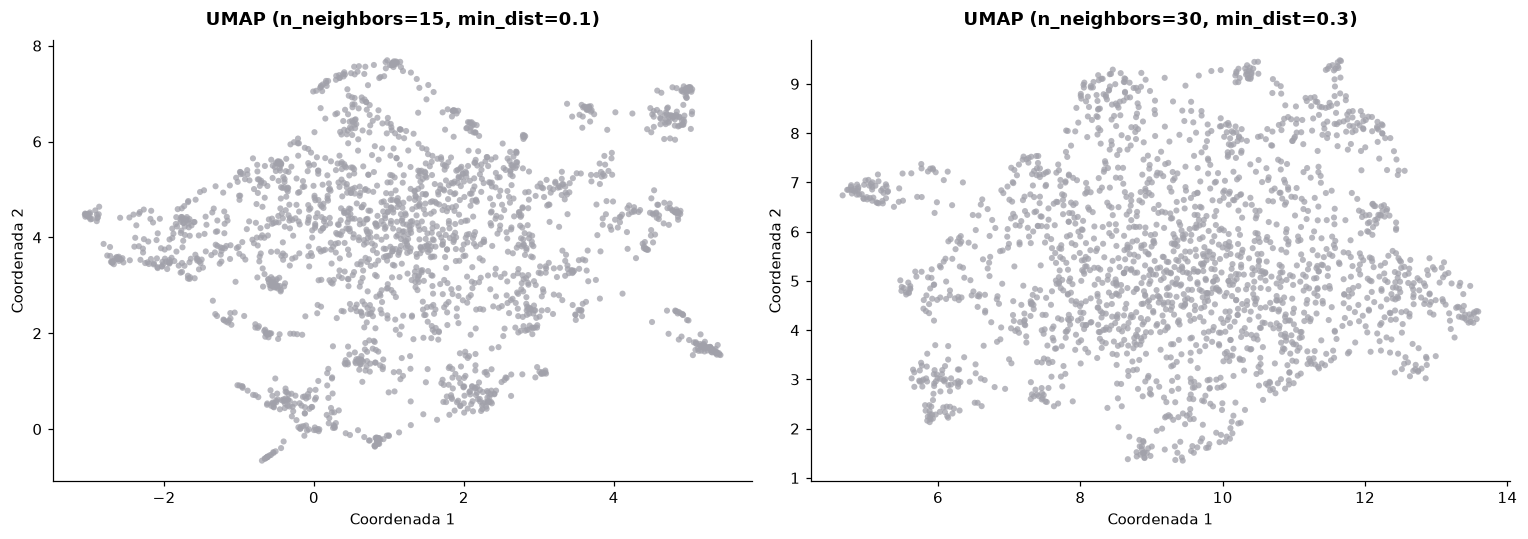

In [ ]:
# Gráficas de comparación
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Evito represntar las labels
plot_groups(ax1, umap_text, [-1] * len(reviews), "UMAP (n_neighbors=15, min_dist=0.1)")
plot_groups(ax2, umap_text_smooth, [-1] * len(reviews), "UMAP (n_neighbors=30, min_dist=0.3)")

plt.tight_layout()
plt.show()

<div style="background-color:#EDF7FF;border:1px solid #7C9DBF;border-left:5px solid #7C9DBF;padding:.8em 1em;margin:1em 0;"><strong>Análisis:</strong> ¿Las dos figuras tienen la misma estructura? ¿Parece haber grupos útiles? ¿Sobre cuál aplicarías clustering?</div>

No, a simple vista se puede observar como la primera figura (n_neighbors=15, min_dist=0.1) es más compacta y se ve como hay una mayor separación entre agrupaciones lo cual puede identificar posibles grupos útiles a diferencia de la segunda gráfica (n_neighbors=30, min_dist=0.3). Que si bien en los extremos parace hacer agrupaciones útiles, no estan muy bien diferenciadas del resto y en el centro de la representación parece haber mucho ruido. 

Para aplicar clustering utilizará la primera representacion (n_neighbors=15, min_dist=0.1) por lo dicho, una mejor separación entre la agrupación de los puntos lo cual nos puede hacer más sencillo en el clustering su clasificación.


## 2.3 Buscando estructuras en los embeddings

Aplica K-means a `E`. Elige `k` entre `{4,6,8}` mediante silhouette, tamaños e interpretabilidad.
Una vez elegido, conserva el mismo `k` en los siguientes escenarios.

<div style="background-color:#EDF7FF;border:1px solid #7C9DBF;border-left:5px solid #7C9DBF;padding:.8em 1em;margin:1em 0;"><strong>Implementación:</strong> Representa en 3 gráficas: silhouette para los tres valores de <code>k</code>, elige <code>k_text</code> (el seleccionado) y guarda los grupos en <code>labels_text</code>. Muestra el clustering sobre la proyección UMAP. Y la distribución de tamaños de cada cluster.<br>Por último, inspecciona tres comentarios representativos de cada uno de los 4 grupos <code>show_representatives</code>.</div>

In [108]:
# Evaluación de Silhouette y ajuste de K-means para los candidados a k
k_candidates = [4, 6, 8]
silhouette_scores = {}
kmeans_models = {}

for k in k_candidates:
    km = KMeans(n_clusters=k, random_state=SEED, n_init=10)
    labels = km.fit_predict(E)
    score = silhouette_score(E, labels, metric='cosine')
    silhouette_scores[k] = score
    kmeans_models[k] = (km, labels)

# Selección de k_text (k=4 según la indicación del enunciado)
k_text = 4 # Por principio de parsimonia al haber una diferencia minima con los otros
kmeans_selected, labels_text = kmeans_models[k_text]

print(f"Silhouette Scores: {silhouette_scores}")
print(f"k_text seleccionado: {k_text}")

Silhouette Scores: {4: 0.042740561068058014, 6: 0.04435227811336517, 8: 0.05082659050822258}
k_text seleccionado: 4


Ahora una vez elegido el k_text paso a hacer las gráficas que se piden, como vemos la diferencia en el Silhouette score es mínima entre los candidatos a k (<0.01) por ende por principio de parsimonia (simplicidad a la hora de interpretar) elijo k=4. Podemos ver la clasificación realizada en el UMAP y luego como el grupo 3 destaca sobre los demás en cuanto a su frecuencia que ronda los 800 (los demás se mantienen en un nievel similar entre ellos alrededor de 400).

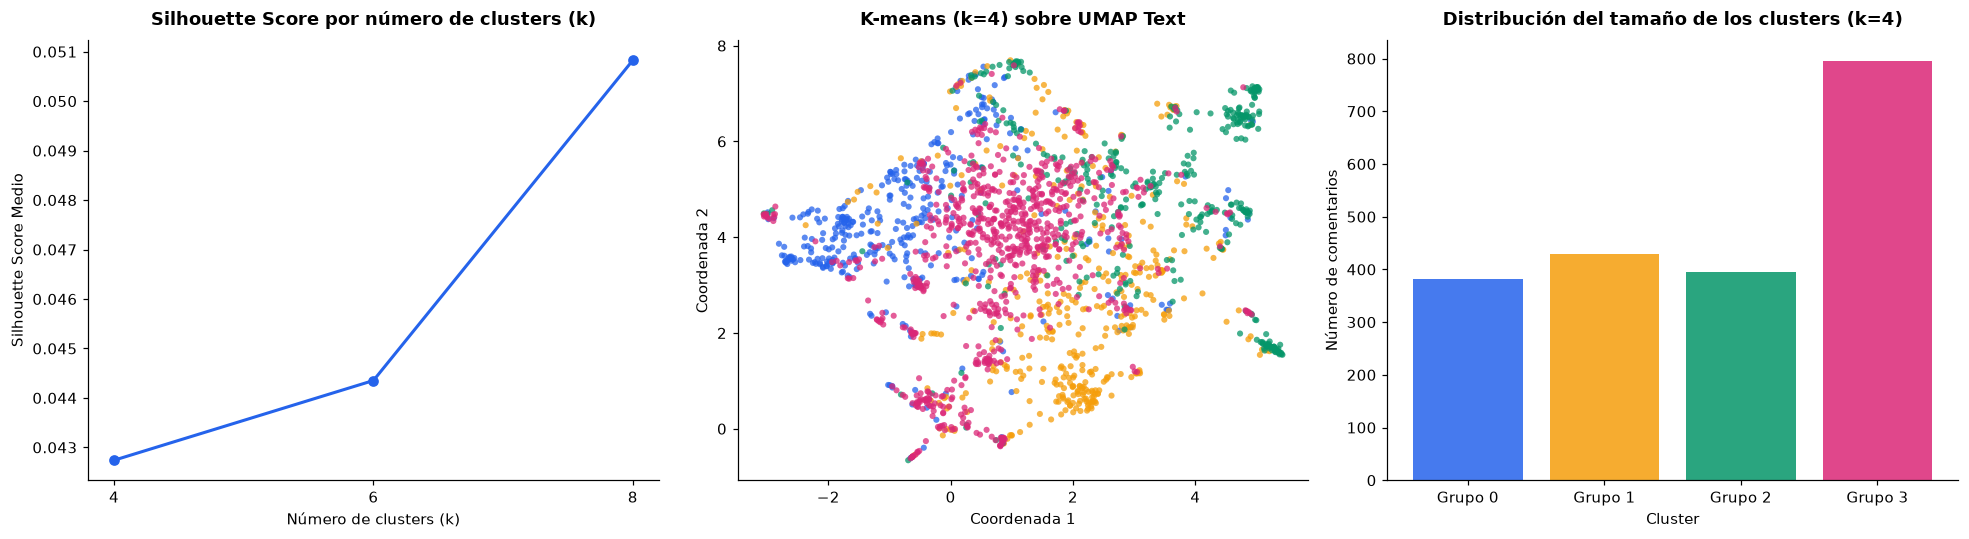

In [112]:
# Representación de las 3 gráficas
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5))

# Gráfica 1: Silhouette Score por valor de k
ax1.plot(k_candidates, [silhouette_scores[k] for k in k_candidates], marker='o', color=COLORS[0], linewidth=2)
ax1.set_title('Silhouette Score por número de clusters (k)', fontweight='bold', pad=10)
ax1.set_xlabel('Número de clusters (k)')
ax1.set_ylabel('Silhouette Score Medio')
ax1.set_xticks(k_candidates)

# Gráfica 2: Clustering sobre la proyección UMAP (la elegida anteriormente)
plot_groups(ax2, umap_text, labels_text, title=f"K-means (k={k_text}) sobre UMAP Text")

# Gráfica 3: Distribución del tamaño de los clusters
counts = pd.Series(labels_text).value_counts().sort_index()
ax3.bar([f"Grupo {i}" for i in counts.index], counts.values, color=[COLORS[i % len(COLORS)] for i in counts.index], alpha=0.85)
ax3.set_title(f"Distribución del tamaño de los clusters (k={k_text})", fontweight='bold', pad=10)
ax3.set_xlabel('Cluster')
ax3.set_ylabel('Número de comentarios')

plt.tight_layout()
plt.show()

Y finalmente tomo una muestra de 3 comentarios por grupo. Se aprecia come efectivamente cada uno captura un tipo de comentario específico.

In [107]:
# Muestro los 3 comentarios más representativos de cada uno de los 4 grupos
show_representatives(reviews, E, labels_text, max_groups=k_text, n=3)


CLUSTER 3 | 795 comentarios
  S0976 · Rust
  Really good game in general. Fun for playing with friends or alone, And maybe meet some new friends
on it too!

  S1331 · Robocraft
  This game is great as it is in early access. The community is active and great. Overall this game is
Highly Recommended!!!!

  S1868 · Team Fortress 2
  Very fun game, good for wasting time and even getting competitive. Hours of fun and fustration
ahead. Highly recommend this game to anyone looking for fun and enjoyable gameplay.


CLUSTER 1 | 429 comentarios
  S0062 · Rust
  The reason i got this game was because my friends told me it would be fun and we could do many
thangs i got the game i played it for a good 50 hours then realiszed it was a pedophile simulaor
naked man chase you down shove their ♥♥♥♥♥ in your face ♥♥♥♥ you hold you hostage and kill you i had
nightmares of old naked men ♥♥♥♥♥♥ me when i played this game i wish there was a way to get my money
back plus there are to many HACKERS

  S0442 · 

<div style="background-color:#EDF7FF;border:1px solid #7C9DBF;border-left:5px solid #7C9DBF;padding:.8em 1em;margin:1em 0;"><strong>Implementación:</strong> Representa en un mapa de calor para cada juego (eje x) y cada cluster (eje y) el porcentaje de comentarios de cada juego (normaliza a 1 cada fila).<br>Calcula el Normalized Mutual Information (NMI) entre cluster y juego como medida de asociación, para saber el grado de correspondencia de los grupos con los juegos.</div>

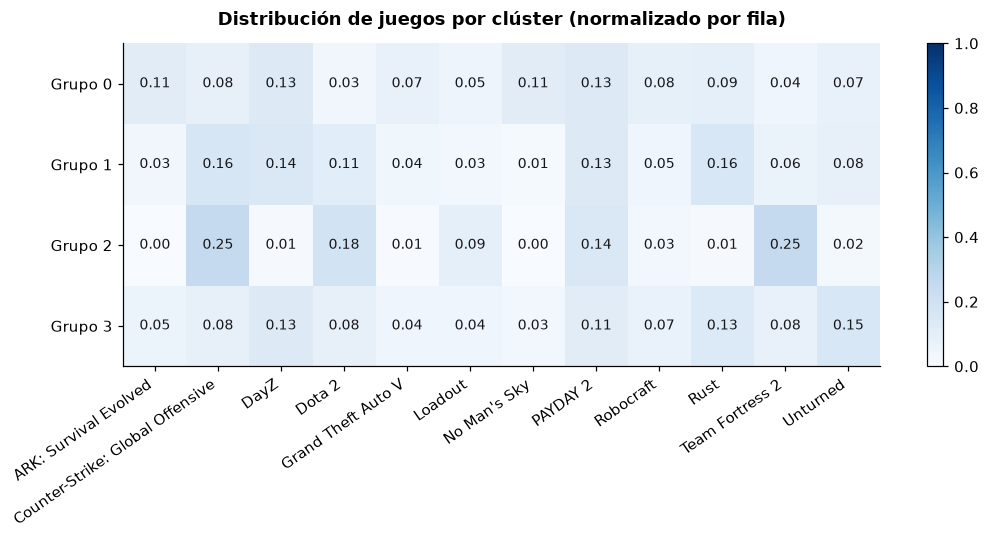

In [118]:
# Matriz de contingencia normalizada por filas directamente (cada fila suma 1)
ct_norm = pd.crosstab(labels_text, reviews['game'], normalize='index')
# Extraigo las etiquetas para los ejes
row_labels = [f"Grupo {i}" for i in ct_norm.index]
col_labels = ct_norm.columns.tolist()

# Mapa de calor resultante de la matriz normalizada
fig, ax = plt.subplots(figsize=(10, 5))
im = heatmap(
    ax, 
    ct_norm, 
    rows=row_labels, 
    columns=col_labels, 
    title="Distribución de juegos por clúster (normalizado por fila)",
    cmap="Blues",
    vmin=0, 
    vmax=1
)
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

Una vez creado el heatmap vemos como hay una concordancia muy baja entre el juego y el grupo al que pertenece, ninguno pasa de un porcentaje más alto que 25% y mayoría se encuentra en un rango de 0% a 10%. Esto queda confirmado por el índice NMI tan cercano a 0 que nos da (0.0785).

In [117]:
# Cálculo del Normalized Mutual Information (NMI)
nmi_value = normalized_mutual_info_score(reviews['game'], labels_text)
print(f"Normalized Mutual Information (NMI) entre juego y clúster: {nmi_value:.4f}")

Normalized Mutual Information (NMI) entre juego y clúster: 0.0785


<div style="background-color:#EDF7FF;border:1px solid #7C9DBF;border-left:5px solid #7C9DBF;padding:.8em 1em;margin:1em 0;"><strong>Análisis:</strong> Asigna un nombre provisional a los 4 grupos inspeccionados. Puedes usar IA para ayudarte a identificar el tema a partir de los comentarios representativos, pero comprueba la propuesta leyendo los textos y cita los identificadores en los que te has basado.</div>

#### Clúster 3: **Reseñas Positivas y Experiencia Multijugador**
* **Nombre provisional:** `Experiencia Positiva`
* **Temática principal:** Comentarios con un tono altamente entusiasta y satisfactorio. Los usuarios destacan la diversión general del juego, el valor de jugar con amigos o en comunidad, y recomiendan encarecidamente la compra.
* **Identificadores de soporte:**
  * `S0976` (*Rust*): Destaca que es un juego muy divertido tanto en solitario como con amigos (*"Really good game in general. Fun for playing with friends or alone..."*).
  * `S1331` (*Robocraft*): Alaba el estado del *Early Access* y la comunidad activa (*"The community is active and great. Overall this game is Highly Recommended!"*).
  * `S1868` (*Team Fortress 2*): Resalta las horas de entretenimiento y la jugabilidad competitiva (*"Very fun game, good for wasting time... Highly recommend this game..."*).

---

#### Clúster 1: **Experiencia Negativa Extrema (Toxicidad, Bugs y Hackers)**
* **Nombre provisional:** `Experiencia Negativa`
* **Temática principal:** Críticas fuertemente negativas expresadas con un lenguaje hostil o despectivo. Agrupa quejas sobre conductas tóxicas/inapropiadas de otros jugadores, presencia de *hackers*, pérdidas absurdas de progreso/objetos y fallos mecánicos graves.
* **Identificadores de soporte:**
  * `S0062` (*Rust*): Queja sobre interacciones tóxicas y presencia de tramposos (*"...realized it was a pedophile simulator... plus there are to many HACKERS"*).
  * `S0442` (*Rust*): Frustración con el sistema de apariciones y la desaparición del inventario al morir (*"...run around the entire map... body had despawned before 4 minutes..."*).
  * `S0779` (*DayZ*): Crítica severa a las decisiones de los desarrolladores frente a fallos del sistema de movimiento (*"...devs have no clue... instead of fixing the fact that if pull out your gun you run the risk of walking off a roof..."*).

---

#### Clúster 2: **Análisis de Diseño, Contenido y Modelo de Negocio**
* **Nombre provisional:** `Análisis Técnico`
* **Temática principal:** Reseñas de carácter descriptivo y evaluativo. Los usuarios analizan las mecánicas de juego, el motor gráfico, la variedad de clases/modos y, especialmente, la justicia del modelo monetario (*Free to Play* sin ser *Pay to Win*).
* **Identificadores de soporte:**
  * `S0228` (*Loadout*): Analiza las mecánicas, servidores, optimización y el modelo estético (*"TF2 pay model. Pay for cosmetics ONLY. This is not a Pay to Win game"*).
  * `S1257` (*Team Fortress 2*): Revisa la historia del juego, el motor *Source* y el sistema de intercambios (*"It has Trading, Modes... using source engine with good physics..."*).
  * `S1910` (*Team Fortress 2*): Destaca la variedad de clases y la calidad del multijugador gratuito (*"There are lots of classes to choose from... anyways, it's free to play"*).

---

#### Clúster 0: **Problemas Rendimiento Técnico y Optimización**
* **Nombre provisional:** `Fallos Técnicos`
* **Temática principal:** Comentarios centrados de forma exclusiva en la imposibilidad técnica de jugar debido a *bugs*, congelamientos del sistema (*crashes*), tirones (*stuttering*), caídas de fotogramas (*lag/low FPS*) y un consumo ineficiente de memoria RAM.
* **Identificadores de soporte:**
  * `S0503` (*No Man's Sky*): Señala problemas de *lag* incluso con configuración gráfica al mínimo (*"...a lot of bugs and even when i put everything on LOW still lags..."*).
  * `S0648` (*ARK: Survival Evolved*): Detalla bloqueos del equipo por uso de memoria RAM e incapacidad de conectar a servidores (*"...causes computer to freeze even though my computer has 8GB of ram... client error"*).
  * `S0885` (*DayZ*): Reporta la imposibilidad de jugar por la falta de fluidez (*"I could not play this game once because of how laggy and buggy it is..."*).

Lee los 20 textos siguientes y anota su problema principal
(rendimiento, errores, dificultad/equilibrio, repetición, multijugador, monetización, otro, sin queja clara o ambigua).
Guarda la tabla `audit` antes de ejecutar el modelo de decisiones.

In [119]:
audit_positions = np.random.default_rng(seed+10).choice(len(reviews),20,replace=False)
audit = reviews.loc[audit_positions,['review_id']].copy()
audit['problem'] = ''
display(reviews.loc[audit_positions,['review_id','text']])

,review_id,text
1840,S0406,"Really fun game to play with friends, as it says it is in deep alpha so dont expect no bugs or perfect optomization for your pc. Still a really good game recomend+."
1034,S0691,"great game. dealing drugs, making drugs, getting money for drugs. did i mention there is drugs. seriously get it its real fun"
1259,S0079,"i really like the game but there are a few things that need improvment such as the optimization and the fps, also the rate your food drops (not so much the water) but i found after i killed a few dodo's i was fine.also maybe try to make the agro range on the raptors a little less because if one spots you HOOOOOLLY crap yor goinna want to run.but all and all its not to shabby and there are a few bugs but its only in early access so i cant wait to see what changes are to come :D"
1764,S0709,"What ever you do, DO NOT PLAY THIS GAME.Its so bad i'm not even kidding. It should cost the same as Badrats.Terrible Controls.Horrible Graphics tha kill your computer no matter what GPU you have.Full of 12ies that all you a ♥♥♥♥♥♥ and a ♥♥♥♥. SO Yeah Don't Play this Game"
1391,S1918,I will now say what i have experienced whilst playing this game:-I Immediately Regret My Decision-Game Is Hard-Well Played!-PJSalt-DansGame-BibleThump-Russian-Pinoy-SuicidalPlay at your own risk
1844,S0929,i have being playing this game for a long time now. everyone loves it we love your hard work overkill keep it up all i wish you could do is low fps don't use all u have in it please it will work hopefuly anyway i still love the game:3 .
891,S1429,"A fun game where you rage at ""hackers"" (they're not), smurfs, awps, dak daks, autoshottys at close range and other stuff. This is a good game"
1016,S0222,"Daily crashes during competitive matches for which you get a ban if you don't rejoin, had to validate game cache during a competitive match today and yesterday. You've had enouigh time and money to fix this broken game for a while valve, now stop flipping off your customers and do it."
473,S1272,"but wait. counter strike has 3 versions. cs 1.6, css and csgo. clearly gaben doesnt hate 3. HL3 CONFIRMED.seriously when do we get hl3?"
1959,S1082,"Well, let me tell ya, this is an awesome game, even if i dont have the 4k graphic settings, its still looking good!!!And The Online, if you have friends, it will be the most funny experience ever.So in other words, this game its worth its full price and your (free) time."


In [120]:
# Diccionario con la clasificación manual según el análisis de los 20 textos
problem_mapping = {
    'S0406': 'sin queja clara o ambigua',
    'S0691': 'sin queja clara o ambigua',
    'S0079': 'rendimiento',
    'S0709': 'rendimiento',
    'S1918': 'dificultad/equilibrio',
    'S0929': 'rendimiento',
    'S1429': 'multijugador',
    'S0222': 'errores',
    'S1272': 'otro',
    'S1082': 'sin queja clara o ambigua',
    'S1905': 'monetización',
    'S0335': 'monetización',
    'S0478': 'multijugador',
    'S1808': 'sin queja clara o ambigua',
    'S1946': 'multijugador',
    'S0462': 'sin queja clara o ambigua',
    'S1769': 'dificultad/equilibrio',
    'S0284': 'sin queja clara o ambigua',
    'S0415': 'sin queja clara o ambigua',
    'S1009': 'sin queja clara o ambigua'
}

# Valores a la columna 'problem' de la tabla audit ya creada
audit['problem'] = audit['review_id'].map(problem_mapping)

# Mostrar el resultado final guardado
display(audit)

,review_id,problem
1840,S0406,sin queja clara o ambigua
1034,S0691,sin queja clara o ambigua
1259,S0079,rendimiento
1764,S0709,rendimiento
1391,S1918,dificultad/equilibrio
1844,S0929,rendimiento
891,S1429,multijugador
1016,S0222,errores
473,S1272,otro
1959,S1082,sin queja clara o ambigua


<div style="background:#b8e7ff;color:black;padding:1.2em 1.4em;border-radius:8px;">
<strong style="font-size:1.35em;">Ahora vamos a cambiar qué significa "parecerse".</strong><br><br>
Hasta aquí hemos agrupado por similitud general del texto. El equipo necesita encontrar problemas investigables.<br>
Vamos a preguntar a un modelo de decisiones por atributos concretos de cada comentario y volver a agrupar.
</div>

## 2.4 Crear seis features con Laya

### De pedir etiquetas a un LLM a utilizar un modelo de decisiones

Una posibilidad sería enviar cada comentario a un LLM generativo y pedirle que escribiera una etiqueta o un JSON.
Eso permite formular tareas flexibles y pedir explicaciones, pero para este paso solo necesitamos decisiones numéricas con significado estable:
"¿qué problema principal describe?" o "¿hay una queja sobre controles?". Generar una explicación completa para cada comentario no es necesario.

Un LLM generativo produce su respuesta como una secuencia de tokens. Puede utilizar esquemas y decodificación restringida para devolver JSON válido. No hay que confundir validez del formato con un juicio correcto. Un **modelo de decisiones** toma el texto y una pregunta con alternativas o escala, y obtiene directamente las puntuaciones de las respuestas permitidas. Puede incorporarse a un programa como una regla flexible, sin tener que extraer una etiqueta de una respuesta redactada.

**Jev**, de TypeSafe, es un ejemplo de esta idea: decisiones tipadas en lugar de generación libre.
Su documentación presenta el contraste entre generar tokens y producir las puntuaciones de las opciones en paralelo:
[presentación de System One y Jev](https://typesafe.ai/blog/introducing-system-one-models-and-jev).
En esta actividad usaremos **Laya**, una alternativa con pesos disponibles y licencia Apache 2.0, que podemos ejecutar localmente. No necesitaremos una cuenta o una API de Jev.

### Cómo funciona Laya

Usamos el checkpoint inglés `typed-decisions`, técnicamente: basado en un encoder bidireccional ModernBERT-large y una cabeza de decisión,
con unos 421 millones de parámetros. **Combina el estado con las instrucciones y criterios de la pregunta, representa ese contexto
y puntúa las alternativas en una pasada por la red, sin generar una respuesta token a token**.
Esta descripción corresponde al checkpoint elegido. No presupone que todos los modelos de decisiones compartan arquitectura.
Consulta la [ficha de la familia Laya](https://huggingface.co/convaiinnovations/laya) y el [SDK y ejemplos oficiales](https://github.com/NandhaKishorM/laya).

No entrenaremos un clasificador distinto para cada feature: **describiremos su significado en el esquema de la pregunta y aplicaremos el modelo preentrenado**. Lo usaremos como un clasificador *zero-shot* (sin entrenamiento *ad-hoc*).
La definición de las categorías y sus criterios sigue siendo una decisión nuestra. Una salida numérica no elimina ese trabajo de diseño.

Las ventajas para esta práctica son **salida acotada (a lo que especifiquemos), integración sencilla, ejecución local y ausencia de generación innecesaria**,  no es autorregresivo como los LLMs, solo usa una pasada por entrada, lo que acelera y abarata mucho el proceso de etiquetado.
También puede fallar ante sarcasmo, lenguaje informal, varios problemas simultáneos o preguntas mal definidas. Sus puntuaciones tampoco se convierten automáticamente en probabilidades calibradas sobre Steam.

Estamos usando Laya porque se trata de un modelo pequeño que podemos correr en máquinas discretas, hay alternativas más completas. Puedes consultarlas y compararlas en este [leaderboard de modelos de decisión](https://benchmarkheaven.com/jev-models).

### Las seis features propuestas

Laya recibe un **estado** (el comentario) y preguntas con un tipo de respuesta:
`choice` (opción), `score` (escala) o `noul` (sí/no). Usaremos el checkpoint `typed-decisions` y una clasificación `choice`
del **problema principal**. Sus puntuaciones para seis categorías se convierten en features continuas en `[0,1]`.
No deben interpretarse como probabilidades perfectamente calibradas para este dominio.

| Feature | Pregunta de dominio |
|---|---|
| `performance_complaint` | ¿Hay una queja sobre FPS, fluidez o carga? |
| `bugs_complaint` | ¿Describe un error, un bloqueo o un cierre inesperado? |
| `balance_complaint` | ¿Critica dificultad o equilibrio de las mecánicas? |
| `grind_complaint` | ¿Critica repetición o esfuerzo excesivo para avanzar? |
| `multiplayer_complaint` | ¿Describe problemas de conexión, emparejamiento o cooperación? |
| `monetization_complaint` | ¿Critica compras adicionales, DLC o pagar para obtener ventajas? |

Añade además las opciones `other_complaint` y `no_complaint`, para no forzar todo texto a ser una queja de las seis categorías.
**Mencionar un aspecto no equivale a quejarse de él.** Las instrucciones deben indicar esa diferencia.
Las ocho puntuaciones compiten y suman aproximadamente uno, las seis features seleccionadas suman como máximo uno.
No renormalices esas seis columnas: un comentario sin quejas debe conservar puntuaciones pequeñas.
Esta clasificación simplifica comentarios con varios problemas al principal. Es una limitación que debes analizar.
Una única pregunta `choice` resulta más económica en CPU que seis preguntas binarias independientes.
Consulta la [ficha de Laya](https://huggingface.co/convaiinnovations/laya) y su [SDK](https://github.com/NandhaKishorM/laya).

In [121]:
LAYA_REVISION = '7b928d828b7b0e022f929d9bd2e44165aa270148'
agent = load_laya(LAYA_REVISION,device='cpu')

# Ejemplo binario para familiarizarse con el formato choice.
example_questions = {
    'performance_check': {'type':'choice',
        'instructions':'Does this review complain about technical performance?',
        'criteria':{'performance_complaint':'Poor FPS, stuttering or slow loading.',
                    'no_performance_complaint':'Performance praised or unmentioned; no performance complaint.'}}
}
example_text = 'I like the story, but the frame rate drops to 10 FPS and stutters.'
print(agent.predict(example_text,example_questions)['answers'])

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]c:\Users\axton\anaconda3\envs\pec2_20261\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\axton\.cache\huggingface\hub\models--convaiinnovations--laya. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Fetching 5 files: 100%|██████████| 5/5 [01:50<00:0

{'performance_check': {'type': 'choice', 'choice': 'performance_complaint', 'probabilities': {'performance_complaint': 0.8559, 'no_performance_complaint': 0.1441}, 'confidence': 0.4052, 'answer_confidence': 0.8559, 'action': {'act_probability': 1.0}}}


<div style="background-color:#EDF7FF;border:1px solid #7C9DBF;border-left:5px solid #7C9DBF;padding:.8em 1em;margin:1em 0;"><strong>Implementación:</strong> Define <code>questions_base</code> con una pregunta <code>choice</code> en inglés y ocho opciones: las seis categorías de la tabla, <code>other_complaint</code> y <code>no_complaint</code>. Escribe criterios claros para cada opción. Obtén las puntuaciones de 20 comentarios, revisa manualmente cuatro aciertos y dos errores o ambigüedades y después procesa la muestra completa con <code>laya_features</code>. Guarda el DataFrame como <code>F_base</code>. Representa en un mapa de calor las puntuaciones de 15 comentarios identificados por <code>review_id</code>.</div>

In [ ]:
# Definición del diccionario de preguntas choice (8 categorías)
questions_base = {
    'main_problem': {
        'type': 'choice',
        'instructions': (
            'Determine the single primary problem reported in the game review. '
            'Mentioning an aspect does NOT constitute a complaint; distinguish actual complaints from mere mentions or praise. '
            'If no clear complaint is made but the review is negative, select other_complaint otherwise select no_complaint.'
        ),
        'criteria': {
            'performance_complaint': 'Complaints about low FPS, smoothness/fluidity, or slow loading times.',
            'bugs_complaint': 'Describes a software bug or error, freezing, or an unexpected crash.',
            'balance_complaint': 'Criticizes difficulty, controls, or game mechanics balance.',
            'grind_complaint': 'Criticizes repetition or excessive effort required to progress.',
            'multiplayer_complaint': 'Describes connection, matchmaking, or co-op/multiplayer problems.',
            'monetization_complaint': 'Criticizes additional purchases, DLCs, loot boxes, or pay-to-win mechanics.',
            # Categorias adicionales para capturar quejas fuera de las 6 categorías principales:
            'other_complaint': 'A clear complaint is present, but it does not fit the 6 specific categories above.',
            'no_complaint': 'No clear complaint present; the review is positive, neutral, purely informational, or satirical.'
        }
    }
}

# Lista completa con TODAS las 8 columnas producidas por la pregunta choice (para el heatmap)
target_cols = [
    'performance_complaint', 'bugs_complaint', 'balance_complaint',
    'grind_complaint', 'multiplayer_complaint', 'monetization_complaint',
    'other_complaint', 'no_complaint'
]

# Puntuaciones para los 20 comentarios de la auditoría
audit_texts = reviews.loc[audit.index, 'text']
audit_scores = laya_features(agent, audit_texts, questions_base)

# Construcción de la tabla de evaluación incluyendo review_id, texto, etiqueta manual y predicción para comparar
audit_eval = audit_scores.copy()
audit_eval['review_id'] = audit['review_id'].values
audit_eval['text'] = audit_texts.values  # Incluimos el texto del comentario para verificar
audit_eval['manual_label'] = audit['problem'].values
audit_eval['pred_label'] = audit_scores.idxmax(axis=1)

# Mostrar la tabla resultada con el comentario incluido
display(audit_eval[['review_id', 'text', 'manual_label', 'pred_label']])

Laya: features:   0%|          | 0/20 [00:00<?, ?it/s]

Laya: features: 100%|██████████| 20/20 [01:12<00:00,  3.64s/it]

Cache: 0/20; inferencias nuevas: 20; tiempo: 72.8 s


,review_id,text,manual_label,pred_label
0,S0406,"Really fun game to play with friends, as it says it is in deep alpha so dont expect no bugs or perfect optomization for your pc. Still a really good game recomend+.",sin queja clara o ambigua,no_complaint
1,S0691,"great game. dealing drugs, making drugs, getting money for drugs. did i mention there is drugs. seriously get it its real fun",sin queja clara o ambigua,other_complaint
2,S0079,"i really like the game but there are a few things that need improvment such as the optimization and the fps, also the rate your food drops (not so much the water) but i found after i killed a few dodo's i was fine.also maybe try to make the agro range on the raptors a little less because if one spots you HOOOOOLLY crap yor goinna want to run.but all and all its not to shabby and there are a few bugs but its only in early access so i cant wait to see what changes are to come :D",rendimiento,bugs_complaint
3,S0709,"What ever you do, DO NOT PLAY THIS GAME.Its so bad i'm not even kidding. It should cost the same as Badrats.Terrible Controls.Horrible Graphics tha kill your computer no matter what GPU you have.Full of 12ies that all you a ♥♥♥♥♥♥ and a ♥♥♥♥. SO Yeah Don't Play this Game",rendimiento,bugs_complaint
4,S1918,I will now say what i have experienced whilst playing this game:-I Immediately Regret My Decision-Game Is Hard-Well Played!-PJSalt-DansGame-BibleThump-Russian-Pinoy-SuicidalPlay at your own risk,dificultad/equilibrio,bugs_complaint
5,S0929,i have being playing this game for a long time now. everyone loves it we love your hard work overkill keep it up all i wish you could do is low fps don't use all u have in it please it will work hopefuly anyway i still love the game:3 .,rendimiento,no_complaint
6,S1429,"A fun game where you rage at ""hackers"" (they're not), smurfs, awps, dak daks, autoshottys at close range and other stuff. This is a good game",multijugador,no_complaint
7,S0222,"Daily crashes during competitive matches for which you get a ban if you don't rejoin, had to validate game cache during a competitive match today and yesterday. You've had enouigh time and money to fix this broken game for a while valve, now stop flipping off your customers and do it.",errores,bugs_complaint
8,S1272,"but wait. counter strike has 3 versions. cs 1.6, css and csgo. clearly gaben doesnt hate 3. HL3 CONFIRMED.seriously when do we get hl3?",otro,bugs_complaint
9,S1082,"Well, let me tell ya, this is an awesome game, even if i dont have the 4k graphic settings, its still looking good!!!And The Online, if you have friends, it will be the most funny experience ever.So in other words, this game its worth its full price and your (free) time.",sin queja clara o ambigua,no_complaint


Revisando los resultados sobre esos 20 textos identifico cuatro aciertos como pueden ser los casos de no_complaint finales ids S0284, S0415, S01009 y S0462 la mayoría de ellos hablan en general del juego comentando lo que les gusta y por ende no entran en una queja. Dos errores o ambigüedades podian ser el S0079 que lo clasifica como bugs_complaint cuando habla tambien de problemas de rendimiento, entiendo que ha querido priorizar el comentario d elos bugs por ello es amiguo. El otro caso es S1272 que habla de una teoría de por qué el halflife 3 va a salir y laya lo clasifica como un bugs_complaint siendo un comentario que ni si quiera es una queja.

Ahora después de comprobar con los 20 de prueba paso a hacerlo sobre el conjunto de los 2000 comentarios completo.

In [142]:
# Procesamiento de la muestra completa y guardado en F_base 
F_base = laya_features(agent, reviews['text'], questions_base)

Laya: features:   0%|          | 0/2000 [00:00<?, ?it/s]

Laya: features: 100%|██████████| 2000/2000 [1:59:47<00:00,  3.59s/it] 

Cache: 103/2000; inferencias nuevas: 1897; tiempo: 7187.5 s


Finalmente termino por representar el mapa de calor para 15 comentarios.

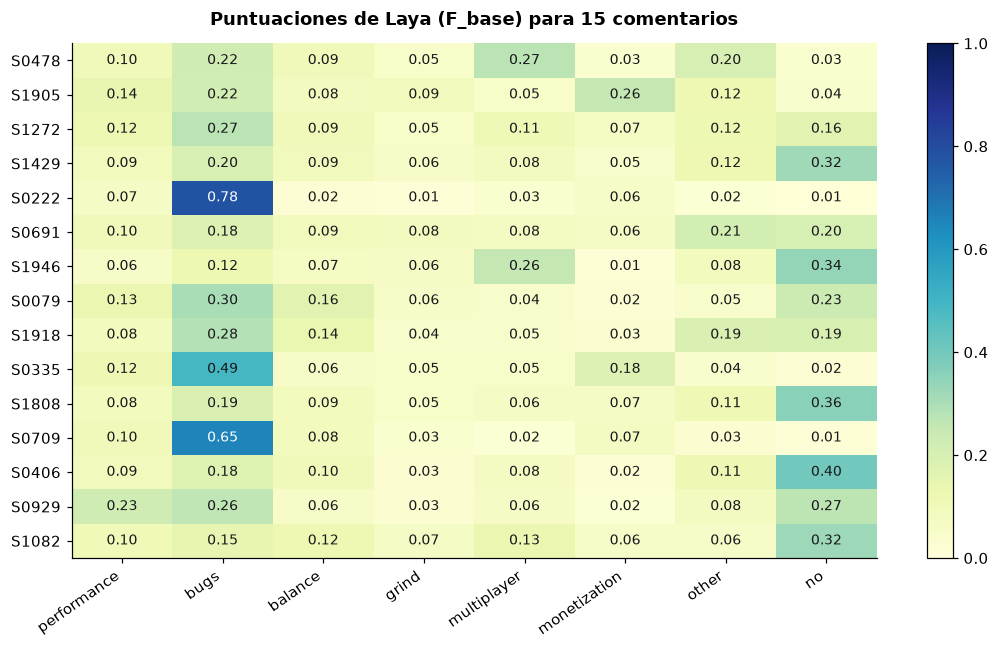

In [143]:
# Mapa de calor para 15 comentarios identificados por review_id
sample_ids = audit['review_id'].head(15).tolist() # tomo los de audit para tardar menos y tener un ejemplo reproducible
sub_df = reviews[reviews['review_id'].isin(sample_ids)]

fig, ax = plt.subplots(figsize=(10, 6))
im = heatmap(
    ax, 
    matrix=F_base.loc[sub_df.index].values, 
    rows=sub_df['review_id'].tolist(), 
    columns=[col.replace('_complaint', '') for col in target_cols], 
    title="Puntuaciones de Laya (F_base) para 15 comentarios",
    cmap="YlGnBu",
    vmin=0.0, 
    vmax=1.0
)
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

<div style="background-color:#EDF7FF;border:1px solid #7C9DBF;border-left:5px solid #7C9DBF;padding:.8em 1em;margin:1em 0;"><strong>Análisis:</strong> ¿Encuentras alguna feature casi constante? ¿Hay comentarios positivos clasificados como quejas? Cita dos comentarios concretos y explica cómo un error del clasificador puede alterar las distancias y el clustering.</div>

Si, se aprecia como la feature de bugs y de no_complain es casi constante, en todas las reseñas suele aparecer con una puntuación por encima del resto. Si hay alguno, podemos identificar en concreto los siguientes:

S0691 - great game. dealing drugs, making drugs, getting money for drugs. did i mention there is drugs. seriously get it its real fun
S1272 - but wait. counter strike has 3 versions. cs 1.6, css and csgo. clearly gaben doesnt hate 3. HL3 CONFIRMED.seriously when do we get hl3?

El segundo es un comentario más abierto pero es que no hay otro que esté mal clasificado siendo positivo y metido como una queja, por ello le he puesto. Los errores en el clasificador que asignan valores elevados de queja a comentarios positivos, que deberían estar en un grupo de no_complain, desplazan drásticamente sus vectores en el espacio de características. Esto **altera la distancia euclídea** al aproximar artificialmente las reseñas satisfechas a las quejas reales, lo que provoca que algoritmos como K-means las absorban dentro de los clústeres de problemas técnicos, contaminando sus centroides y distorsionando la interpretación temática final de los grupos.


## 2.5 Tu aportación: al menos una feature nueva

Ahora define **al menos una feature adicional que se obtenga mediante Laya**. Debe aportar información distinta a las seis existentes.
Puedes usar una pregunta `choice` con dos alternativas explícitas, `noul` o una escala `score` con niveles claros.
Si usas una escala, normaliza su resultado a `[0,1]`. `laya_features` devuelve cada opción de `choice` como columna. Si usas `noul`, revisa posibles tendencias a responder sí.

Antes de ejecutar, escribe: nombre, pregunta en inglés, significado de sus valores y una hipótesis sobre qué grupo de comentarios podría ayudar a encontrar.
Justifica su utilidad a partir de ejemplos encontrados en el clustering inicial. El nombre del juego, la recomendación del autor
o una etiqueta final del cluster no son una feature válida para este apartado.

<div style="background-color:#EDF7FF;border:1px solid #7C9DBF;border-left:5px solid #7C9DBF;padding:.8em 1em;margin:1em 0;"><strong>Análisis:</strong> Propón tu feature y una hipótesis concreta. ¿Qué aporta respecto a las seis propuestas? ¿En qué comentarios esperas que ayude y en cuáles podría fallar?</div>

Mi feature propuesta es "is_sarcastic" de tipo noul se usa como binaria (que Laya convierte en puntuación continua en 
[0,1]) para clasificar si la review es sarcástica o no. La hipótesis concreta es que añadir una variable de sarcasmo/ironía permitirá identificar reseñas cuyo contenido aparente es positivo o irrelevante pero cuya intención real es humorística o de protesta, separando las quejas literales de la sátira y evitando la contaminación de los clústeres de problemas técnicos.

Frente a las 6 propuestas que se centran en medir categorías de problemas en tono literal (como rendimiento, bugs, etc) la que yo propongo se centra en evaluar el "modo" en el que fue escrito el texto, sirviendo como filtro para aislar el ruido sarcástico del feedback técnico genuino. Nos permite tomar con cuidado una reseña en función del grado de sarcasmo.

Espero que ayude a identificar comentarios que sean memes o sátira (como el de halflife 3) para no considerarlos o reducir su importancia, El problema llega cuando comentarios que se escriben de forma sarcastica esconden quejas genuinas, estos podrían acabar en el mismo saco que los que simplemente son memes sin más importancia. 

<div style="background-color:#EDF7FF;border:1px solid #7C9DBF;border-left:5px solid #7C9DBF;padding:.8em 1em;margin:1em 0;"><strong>Implementación:</strong> Define <code>questions_own</code>, ejecuta Laya para esa pregunta sobre la misma muestra y revisa diez ejemplos. Construye <code>F_plus</code> concatenando <code>F_base</code> y las nuevas columnas. Representa un histograma de la nueva feature y los cinco comentarios con mayor puntuación.</div>

In [149]:
# Esquema questions_own
questions_own = {
    'is_sarcastic': {
        'type': 'noul',
        'instructions': 'Is this game review written using sarcasm, irony, jokes, memes, or exaggerated humor rather than a literal critique?',
        'labels': {
            'false': 'Literal, serious, or straightforward review',
            'true': 'Sarcastic, ironic, joke, or meme review'
        },
        'criteria': {
            'false': 'The review expresses direct thoughts, actual feedback, or genuine praise/complaint without irony.',
            'true': 'The review uses sarcasm, irony, absurd humor, memes, or exaggerated praise to mock or joke.'
        }
    }
}

# Inferencia con Laya para la nueva feature 
F_own = laya_features(agent, reviews['text'], questions_own)

# Revisión de 10 ejemplos de auditoría para la nueva feature
audit_own = F_own.loc[audit.index].copy()
audit_own['review_id'] = audit['review_id'].values
audit_own['text'] = reviews.loc[audit.index, 'text'].values

print("--- Revisión de 10 ejemplos de auditoría para 'is_sarcastic' ---")
display(audit_own[['review_id', 'is_sarcastic', 'text']].head(10))

# Construcción del DataFrame F_plus (concatenando F_base y F_own)
F_plus = pd.concat([F_base, F_own], axis=1)

Laya: features: 100%|██████████| 2000/2000 [00:00<00:00, 234338.30it/s]

Cache: 2000/2000; inferencias nuevas: 0; tiempo: 0.1 s
--- Revisión de 10 ejemplos de auditoría para 'is_sarcastic' ---


,review_id,is_sarcastic,text
1840,S0406,0.5000,"Really fun game to play with friends, as it says it is in deep alpha so dont expect no bugs or perfect optomization for your pc. Still a really good game recomend+."
1034,S0691,0.4756,"great game. dealing drugs, making drugs, getting money for drugs. did i mention there is drugs. seriously get it its real fun"
1259,S0079,0.3762,"i really like the game but there are a few things that need improvment such as the optimization and the fps, also the rate your food drops (not so much the water) but i found after i killed a few dodo's i was fine.also maybe try to make the agro range on the raptors a little less because if one spots you HOOOOOLLY crap yor goinna want to run.but all and all its not to shabby and there are a few bugs but its only in early access so i cant wait to see what changes are to come :D"
1764,S0709,0.3737,"What ever you do, DO NOT PLAY THIS GAME.Its so bad i'm not even kidding. It should cost the same as Badrats.Terrible Controls.Horrible Graphics tha kill your computer no matter what GPU you have.Full of 12ies that all you a ♥♥♥♥♥♥ and a ♥♥♥♥. SO Yeah Don't Play this Game"
1391,S1918,0.3716,I will now say what i have experienced whilst playing this game:-I Immediately Regret My Decision-Game Is Hard-Well Played!-PJSalt-DansGame-BibleThump-Russian-Pinoy-SuicidalPlay at your own risk
1844,S0929,0.3235,i have being playing this game for a long time now. everyone loves it we love your hard work overkill keep it up all i wish you could do is low fps don't use all u have in it please it will work hopefuly anyway i still love the game:3 .
891,S1429,0.5957,"A fun game where you rage at ""hackers"" (they're not), smurfs, awps, dak daks, autoshottys at close range and other stuff. This is a good game"
1016,S0222,0.3208,"Daily crashes during competitive matches for which you get a ban if you don't rejoin, had to validate game cache during a competitive match today and yesterday. You've had enouigh time and money to fix this broken game for a while valve, now stop flipping off your customers and do it."
473,S1272,0.4780,"but wait. counter strike has 3 versions. cs 1.6, css and csgo. clearly gaben doesnt hate 3. HL3 CONFIRMED.seriously when do we get hl3?"
1959,S1082,0.4780,"Well, let me tell ya, this is an awesome game, even if i dont have the 4k graphic settings, its still looking good!!!And The Online, if you have friends, it will be the most funny experience ever.So in other words, this game its worth its full price and your (free) time."


Procedo a representar la distribución de la nueva feature con un histograma, vemos como es una distribución que tiene una cola derecha que se extiende más.

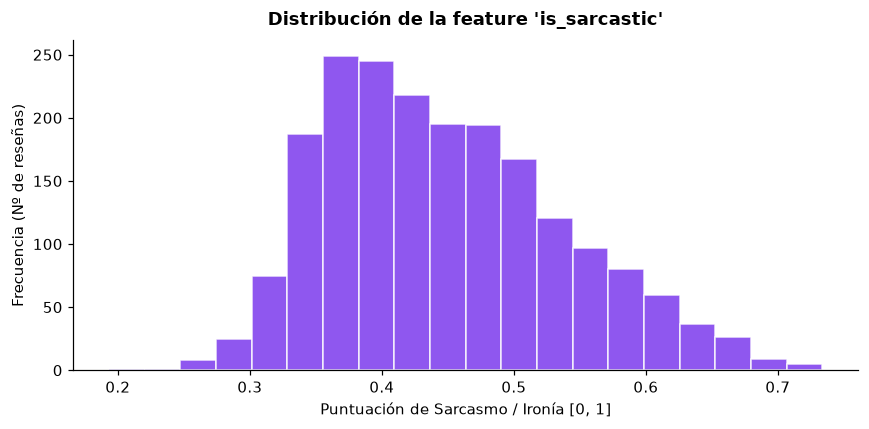

In [150]:
# Histograma de distribución de la nueva feature 'is_sarcastic'
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(F_own['is_sarcastic'], bins=20, color='#7c3aed', edgecolor='white', alpha=0.85)
ax.set_title("Distribución de la feature 'is_sarcastic'", fontweight='bold', pad=10)
ax.set_xlabel("Puntuación de Sarcasmo / Ironía [0, 1]")
ax.set_ylabel("Frecuencia (Nº de reseñas)")
plt.tight_layout()
plt.show()

Nos fijamos ahora en los 5 comentarios con mayor puntuación en esta variable nueva. La mayoría son comentarios haciendo gracia de algo o simplemente siendo sarcastico como esperabamos.

In [151]:
# Top 5 comentarios con mayor puntuación en 'is_sarcastic'
top5_idx = F_own['is_sarcastic'].nlargest(5).index
print("\n=== TOP 5 RESEÑAS CON MAYOR PUNTUACIÓN DE SARCASMO / IRONÍA ===")
for rank, idx in enumerate(top5_idx, 1):
    score = F_own.loc[idx, 'is_sarcastic']
    text_val = reviews.loc[idx, 'text']
    r_id = reviews.loc[idx, 'review_id']
    print(f"\n[{rank}] ID: {r_id} | Score is_sarcastic: {score:.4f}")
    print(f"    Texto: {text_val}")


=== TOP 5 RESEÑAS CON MAYOR PUNTUACIÓN DE SARCASMO / IRONÍA ===

[1] ID: S0426 | Score is_sarcastic: 0.7337
    Texto: loadout is an extremely hilarious take on the moder nday shotter. it's like if team fortress two and Quake had a baby then dropped it on its head and kicked ten timesi rate this game 2 and a half mentally challenged babies out of #@^$^@%@#%( sorry im making soda

[2] ID: S0003 | Score is_sarcastic: 0.7232
    Texto: This game is so much fun with a stupid out look similar to Tf2 runing around in budgie smugglers and your left nut hanging out xD running around naked and twerking HOLY CRAP if you are intrested before downloading see if you like it watch some game play at http://www.youtube.com/watch?v=4wFN49m1k7g

[3] ID: S0085 | Score is_sarcastic: 0.7207
    Texto: Dsmn this game is good and funny as hell you guys should download it and the good thing its free!!!!

[4] ID: S0583 | Score is_sarcastic: 0.7193
    Texto: this game is a peice of ugly...it would be funny if

 
## 2.6 Volver a agrupar: antes, después y tu aportación

Compara **A: embeddings**, **B: seis features** y **C: seis features + la tuya**.
Usa el mismo `k_text`, `n_init=10` y semilla. En B y C conserva las puntuaciones en `[0,1]`:
no estandarices automáticamente una feature casi constante, ya que amplificarías pequeñas variaciones.

El gráfico sobre las coordenadas UMAP iniciales permite observar cómo cambian las asignaciones manteniendo fijo el mapa.
Las proyecciones propias de las features muestran su nueva geometría. Los números y colores de los grupos son arbitrarios entre escenarios.

<div style="background-color:#EDF7FF;border:1px solid #7C9DBF;border-left:5px solid #7C9DBF;padding:.8em 1em;margin:1em 0;"><strong>Implementación:</strong> Calcula <code>labels_base</code> y <code>labels_plus</code> aplicando K-means sobre las features y las features + la tuya. Representa tres gráficas sobre el mismo <code>umap_text</code>, coloreados según A, B y C (misma proyección, distintos colores en base al resultado del K-means).<br>Visualiza en otras dos gráficas las proyecciones UMAP 2D de B y C (esta vez con los vectores obtenidos de Laya) con distancia euclídea, 15 vecinos, <code>min_dist=0.1</code> y la semilla común. Después representa dos mapas de calor de las features medias por grupo, con sus tamaños, y muestra tres comentarios representativos de los 4 grupos más grandes del escenario C.</div>

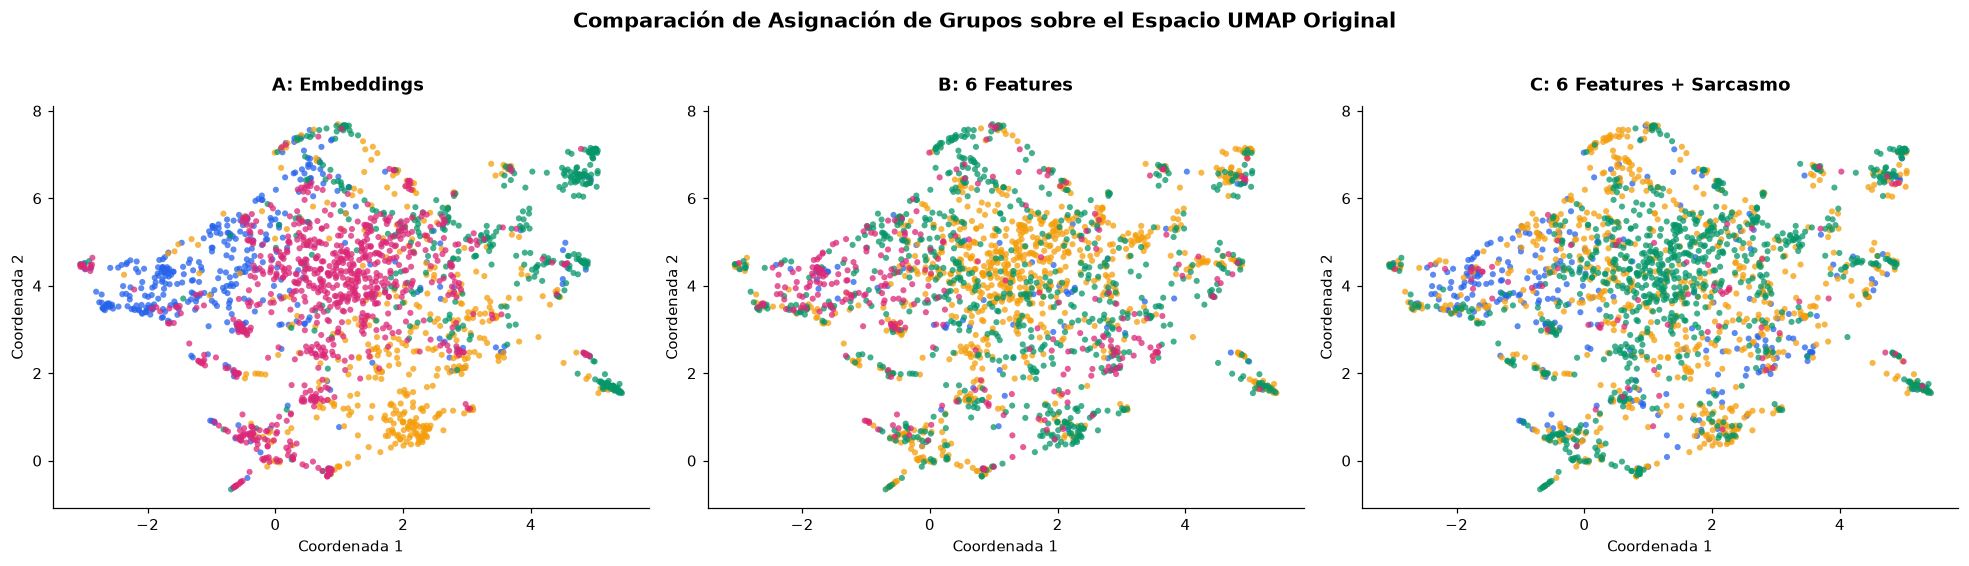

In [ ]:
# Clustering K-means para los escenarios B y C con K=4
kmeans_b = KMeans(n_clusters=k_text, n_init=10, random_state=SEED)
labels_base = kmeans_b.fit_predict(F_base)
kmeans_c = KMeans(n_clusters=k_text, n_init=10, random_state=SEED)
labels_plus = kmeans_c.fit_predict(F_plus)

# Figura con las 3 Gráficas sobre las coordenadas UMAP iniciales (umap_text)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

plot_groups(axes[0], umap_text, labels_text, title="A: Embeddings ")
plot_groups(axes[1], umap_text, labels_base, title="B: 6 Features")
plot_groups(axes[2], umap_text, labels_plus, title="C: 6 Features + Sarcasmo")

plt.suptitle("Comparación de Asignación de Grupos sobre el Espacio UMAP Original", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

Vemos como con 4 grupos de kmeans los casos B y C se vuelven más caóticos que el A y resulta dificil diferenciar grupos. Luego cuando hacemos el umap de B y C resulta que si se aprecian los grupos incluso en C mejor que en B.

c:\Users\axton\anaconda3\envs\pec2_20261\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


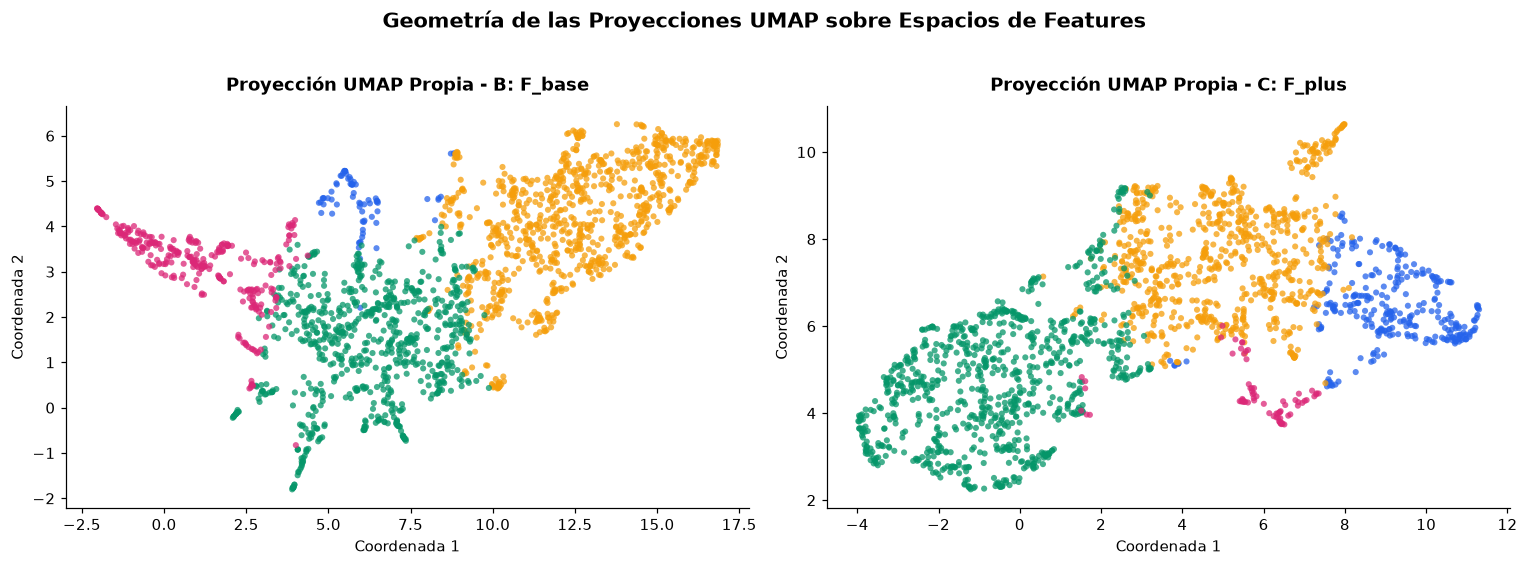

In [154]:
# Proyecciones UMAP propias para B (F_base) y C (F_plus)
umap_reducer = UMAP(n_neighbors=15, min_dist=0.1, metric='euclidean', random_state=SEED)
umap_F_base = umap_reducer.fit_transform(F_base)
umap_F_plus = umap_reducer.fit_transform(F_plus)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_groups(axes[0], umap_F_base, labels_base, title="Proyección UMAP Propia - B: F_base")
plot_groups(axes[1], umap_F_plus, labels_plus, title="Proyección UMAP Propia - C: F_plus")

plt.suptitle("Geometría de las Proyecciones UMAP sobre Espacios de Features", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

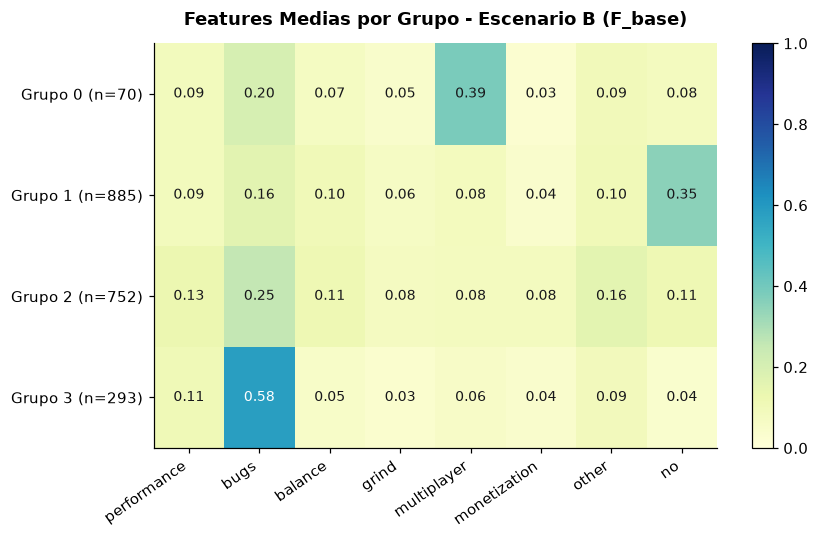

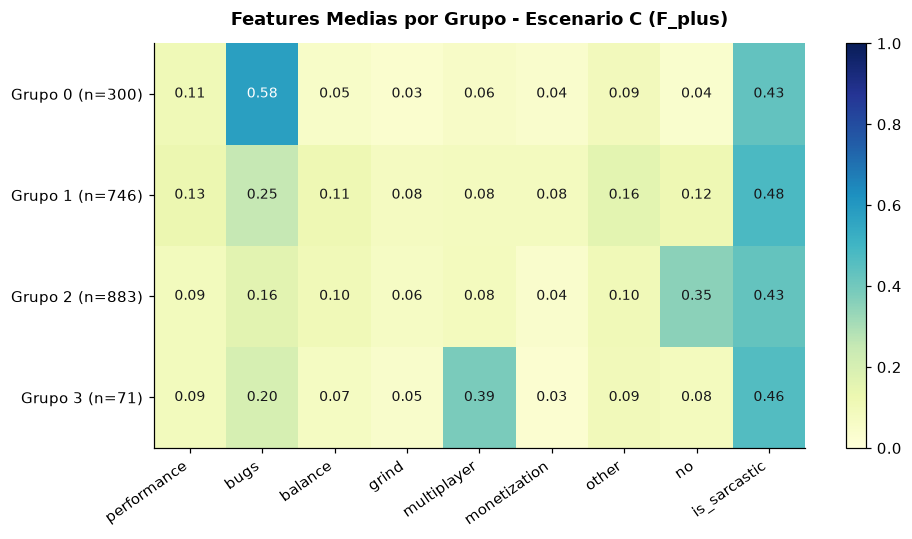

In [155]:
# Mapas de calor de Features Medias por Grupo (B y C) con Tamaños
# Cálculo de medias por clúster
mean_features_b = F_base.groupby(labels_base).mean()
counts_b = pd.Series(labels_base).value_counts().sort_index()
mean_features_c = F_plus.groupby(labels_plus).mean()
counts_c = pd.Series(labels_plus).value_counts().sort_index()

# Visualización del Mapa de Calor para B
fig, ax = plt.subplots(figsize=(8, 5))
rows_b = [f"Grupo {g} (n={counts_b[g]})" for g in mean_features_b.index]
cols_b = [c.replace('_complaint', '') for c in F_base.columns]
im = heatmap(ax, mean_features_b.values, rows_b, cols_b, title="Features Medias por Grupo - Escenario B (F_base)", cmap="YlGnBu", vmin=0.0, vmax=1.0)
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

# Visualización del Mapa de Calor para C
fig, ax = plt.subplots(figsize=(9, 5))
rows_c = [f"Grupo {g} (n={counts_c[g]})" for g in mean_features_c.index]
cols_c = [c.replace('_complaint', '') for c in F_plus.columns]
im = heatmap(ax, mean_features_c.values, rows_c, cols_c, title="Features Medias por Grupo - Escenario C (F_plus)", cmap="YlGnBu", vmin=0.0, vmax=1.0)
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

Los heatmaps muestran como cada grupo tienen una feature característica, mayoritaariamente es bugs, multiplayer y no_complain (entre B y C se cambian el nº de grupo). Pero en C está la feature "is_sarcastic" que practicamente aparece en todos.

In [162]:
# Muestro 3 comentarios representativos de los 4 grupos más grandes (Escenario C)
print("=== COMENTARIOS REPRESENTATIVOS DE LOS GRUPOS MÁS GRANDES (ESCENARIO C) ===")
show_representatives(
    df=reviews,
    vectors=F_plus,
    labels=labels_plus,
    max_groups=4,
    n=3
)

=== COMENTARIOS REPRESENTATIVOS DE LOS GRUPOS MÁS GRANDES (ESCENARIO C) ===

CLUSTER 2 | 883 comentarios
  S0860 · Robocraft
  It's so good and maybe you should add in the game a option to change your name so we don't have to
uninstall the game then reinstall it. But apart from that a fabulous game and i'd give in 8 anna
half / 10. :P

  S0944 · PAYDAY 2
  This game, this game. Its like holding YOUR newborn child. Its like eating nutella out of the jar.
Its like you JUST got the clothes out of the dryer and they are snuggly warm. This game, feels
amazing.

  S1239 · PAYDAY 2
  ♥♥♥♥ing Sick, love it. I went from 1 to level fourty with friends 10/10 best game ever would buy
again


CLUSTER 1 | 746 comentarios
  S0199 · Robocraft
  well i would play it but in the signing up page it asks what 23+1 is and my answer was 24 but it
says its wrong

  S0342 · Team Fortress 2
  Pros of the game:- fun times- hats- bread- international- competitiveCons of the game:- Pay to win
game- Its community- 

<div style="background-color:#EDF7FF;border:1px solid #7C9DBF;border-left:5px solid #7C9DBF;padding:.8em 1em;margin:1em 0;"><strong>Implementación:</strong> Completa una tabla de comparación con silhouette (en el espacio propio), NMI cluster/juego y estabilidad entre semillas <code>{100,101,102}</code> (media de ARI entre las tres particiones).<br>Representa en un mapa de calor la transición de comentarios de la agrupación A a B: cada fila suma 1. Comenta qué observaciones cambian de grupo.</div>

In [164]:
SEEDS = [100, 101, 102]

# Construcción de la Tabla Comparativa de Métricas (A, B y C)
datasets = [
    ('A: Embeddings (E)', E, labels_text, 'cosine'),
    ('B: 6 Features (F_base)', F_base, labels_base, 'euclidean'),
    ('C: 6 Features + Sarcasmo (F_plus)', F_plus, labels_plus, 'euclidean')
]

results = []
for name, data, labels, metric in datasets:
    # Predicciones para las 3 semillas para calcular la estabilidad media (ARI)
    preds = [KMeans(n_clusters=k_text, n_init=10, random_state=s).fit_predict(data) for s in SEEDS]
    ari_mean = np.mean([
        adjusted_rand_score(preds[0], preds[1]),
        adjusted_rand_score(preds[0], preds[2]),
        adjusted_rand_score(preds[1], preds[2])
    ])
    
    results.append({
        'Escenario': name,
        'Silhouette (Espacio propio)': silhouette_score(data, labels, metric=metric),
        'NMI (Cluster / Juego)': normalized_mutual_info_score(reviews['game'], labels),
        'Estabilidad ARI (Semillas 100,101,102)': ari_mean
    })

print("=== TABLA COMPARATIVA DE MÉTRICAS DE CLUSTERING ===")
display(pd.DataFrame(results).round(4))

=== TABLA COMPARATIVA DE MÉTRICAS DE CLUSTERING ===


,Escenario,Silhouette (Espacio propio),NMI (Cluster / Juego),"Estabilidad ARI (Semillas 100,101,102)"
0,A: Embeddings (E),0.0427,0.0785,0.8475
1,B: 6 Features (F_base),0.3831,0.0267,0.9903
2,C: 6 Features + Sarcasmo (F_plus),0.3330,0.0262,0.9698


Vemos en la tabla como se confirma la idea de que la nueva feature que incluí realmente no nos está ayudando tanto a la clasificación pero respecto a la situación A si que mejora (B y C) tanto en Silhouette como estabilidad ARI (tiene muy buena consistencia). He de decir que B sería la mejor situación posible pero muy cerca está C con la feature nueva (la está lastrando). Destacar que el NMI pierde valor en B y C porque las feature fuerzan a laya a ignorar el juego y centrarse en agrupar por el tipo de problema.

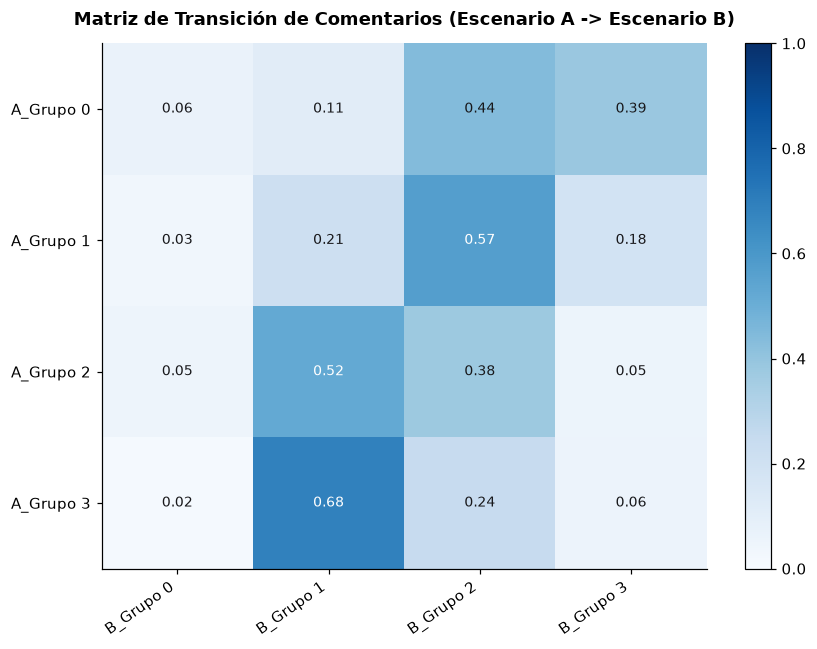

In [165]:
# Matriz de Transición de A a B (Normalizada por filas: cada fila suma 1.0)
ct_AB = pd.crosstab(labels_text, labels_base)
transition_matrix = ct_AB.div(ct_AB.sum(axis=1), axis=0).values

fig, ax = plt.subplots(figsize=(8, 6))
im = heatmap(
    ax=ax, 
    matrix=transition_matrix, 
    rows=[f"A_Grupo {i}" for i in range(k_text)], 
    columns=[f"B_Grupo {j}" for j in range(k_text)], 
    title="Matriz de Transición de Comentarios (Escenario A -> Escenario B)",
    cmap="Blues", 
    vmin=0.0, 
    vmax=1.0
)
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

En cuanto al paso de A a B vemos como la mayoría de grupos se mantienen iguales (en la diagonal) a excepción del A_grupo 3 que pasa a B_grupo 1 casi por completo. También A_grupo 0 pasa a dividirse en 2 B_grupo 2 y 3. 

<div style="background-color:#EDF7FF;border:1px solid #7C9DBF;border-left:5px solid #7C9DBF;padding:.8em 1em;margin:1em 0;"><strong>Análisis:</strong> ¿Ha mejorado la utilidad del clustering para investigar incidencias? ¿Qué añade tu feature? Propón tres prioridades apoyadas en identificadores concretos de comentarios. Distingue claridad visual, estabilidad y utilidad. No compares silhouette entre espacios como si midiera la misma geometría.</div>

A mejorado en el caso B por su puesto pero mi feature (caso C) no parece mejorarlo. Si observamos la tabla de metricas clustering vemos como el caso C siempre esta un poco por debajo del B. Se puede apreciar visualmente en los graficos umap con la clasificación como el caso C se vuelve más confuso en cuanto a su clasificación. Por tanto mi feature más que añadir parece incordiar un poco (podemos ver en el heatmap de los grupos como todos tienen un alto % de sarcasmo lo cual no es de ayuda para discriminar a que se refiere cada uno).

Las prioridades en las que habría que centrarse las enfocaría a cambiar la feature añadida a otra que nos permita hacer una mejor clasificación. Como he comentado antes el escenario C no mejora el escenario B por ende debemos cambiar la feature añadida.

Claridad Visual: Las proyecciones UMAP del Escenario C muestran fronteras bien definidas y separadas entre tipologías de incidencias, a diferencia de la nube dispersa e intrincada del Escenario A.

Estabilidad: La estabilidad evaluada con la media de ARI entre semillas sube de 0.8475 en A a 0.9903 en b y un poco menos en caso C (0.9698), garantizando que los grupos de incidencias sean altamente replicables e independientes de la inicialización de K-means.

Utilidad: Los grupos de B y C tienen una interpretación directa basada en métricas continuas ([0,1]), permitiendo priorizar directamente por impacto y tipo de fallo. A pesar de eso sólo un par de features destacan sobre el resto y algunos grupos no tienen una feature que los caracterice como se muestra en el heatmap.

No se debe comparar la puntuación absoluta de Silhouette entre el Escenario A (0.0427) y los Escenarios B/C (0.3831 / 0.3330) como si midieran la misma geometría. El Escenario A evalúa la compacidad sobre un espacio denso de alta dimensionalidad con métrica coseno, mientras que B y C evalúan distancias euclídeas en subespacios de 6 y 7 dimensiones acotadas en $[0,1]$. La mayor puntuación en B/C refleja una geometría comprimida, no necesariamente una "mejor" segmentación.

<div style="background-color:#EDF7FF;border:1px solid #7C9DBF;border-left:5px solid #7C9DBF;padding:.8em 1em;margin:1em 0;"><strong>Análisis:</strong> ¿Qué es mejor, hacer el clustering en alta dimensionalidad o baja? ¿En qué casos puede tener sentido uno u otro?</div>

No existe un enfoque mejor que otro, todo depende de la situación. Normalmente suele preferirse un clustering de **baja dimensionalidad** por evitar la maldición de la dimensionalidad (a más dimensiones más dificil es interpretar el resultado) y nos permite obtener fronteras de grupos mejor delimitadas y con un menor coste computacional. 

Por otro lado el clustering de **alta dimensionalidad** resulta conveniente para tratar con datos dispersos, opera eficazmente sin distorsionar el espacio, o cuando se aplican técnicas de *preclustering* (como el algoritmo Canopy) para acotar y acelerar el cálculo previo en conjuntos de datos masivos.

En cuanto a nuestro caso yo diría que un punto medio sería el óptimo por lo que hemos visto anteriormente, con demasiadas dimensiones perdemos interpretabilidad y con pocas no logramos clasificar adecuadamente por ello el caso que mejor resultado nos ha dado es el B.